# Cleaning and Normalizing the IMDb Movies by Year Dataset

This notebook takes the combined file built by the guide notebook, `imdb_movies_1920_2026.csv` (106,999 films, 98 columns), and turns it into a clean dataset.

It has two parts:

1. **Analysis (sections 3 to 12).** Each section looks at one aspect of the data: the column inventory, redundant columns, missing values, types and memory, the certificate (age rating), categorical fields, numeric outliers, text quality and the plot text. Charts and tables show the evidence, and section 12 sums it up.
2. **Cleanup (sections 13 to 28).** Section 13 lists the cleanup steps. The following sections apply them one by one, check the result, save it to `/kaggle/working` and compare it with the input:

| File | Contents |
| --- | --- |
| `imdb_movies_1920_2026_clean.csv` | The clean table. List and record columns are JSON text. |
| `imdb_movies_1920_2026_clean.parquet` | The same table with its types kept. Lists and records are native nested columns. |
| `imdb_movies_1920_2026_clean_dictionary.csv` | Every column with its type and description. |

A full run takes about 10 minutes, most of it spent lemmatizing the plots with spaCy.

<h3 style="font-family: 'Segoe UI', Tahoma, Geneva, Verdana, sans-serif; color: #2c3e50; margin-top: 40px;">Contact Me</h3>

<p style="font-size: 16px; color: #555;">
  If you notice anything lacking, spot an issue with this notebook, or have suggestions for improvements, feel free to reach out through any of the platforms below:
</p>

<table style="font-family: 'Segoe UI', Tahoma, Geneva, Verdana, sans-serif; border-collapse: collapse; width: 100%; max-width: 600px;">
  <tbody>
    <tr>
      <td style="padding: 10px;">
        <a href="https://raedaddala.github.io/" target="_blank">
          <img src="https://img.shields.io/badge/Website-raedaddala.github.io-222222?style=for-the-badge&logo=githubpages" alt="Website Badge"/>
        </a>
      </td>
    </tr>
    <tr>
      <td style="padding: 10px;">
        <a href="https://www.linkedin.com/in/addalaraed/" target="_blank">
          <img src="https://img.shields.io/badge/LinkedIn-Raed_Addala-blue?style=for-the-badge&logo=linkedin" alt="LinkedIn Badge"/>
        </a>
      </td>
    </tr>
    <tr>
      <td style="padding: 10px;">
        <a href="https://www.researchgate.net/profile/Raed-Addala" target="_blank">
          <img src="https://img.shields.io/badge/ResearchGate-Raed_Addala-00CCBB?style=for-the-badge&logo=researchgate&logoColor=white" alt="ResearchGate Badge"/>
        </a>
      </td>
    </tr>
    <tr>
      <td style="padding: 10px;">
        <a href="https://x.com/AddalaRaed" target="_blank">
          <img src="https://img.shields.io/badge/Twitter-@AddalaRaed-1DA1F2?style=for-the-badge&logo=twitter" alt="Twitter Badge"/>
        </a>
      </td>
    </tr>
    <tr>
      <td style="padding: 10px;">
        <a href="mailto:addala.raed@gmail.com">
          <img src="https://img.shields.io/badge/Gmail-addala.raed@gmail.com-D14836?style=for-the-badge&logo=gmail" alt="Gmail Badge"/>
        </a>
      </td>
    </tr>
    <tr>
      <td style="padding: 10px;">
        <a href="https://github.com/RaedAddala" target="_blank">
          <img src="https://img.shields.io/badge/GitHub-RaedAddala-181717?style=for-the-badge&logo=github" alt="GitHub Badge"/>
        </a>
      </td>
    </tr>
  </tbody>
</table>

## 1. Setup

Add the output of the guide notebook as an input. Kaggle mounts it under `/kaggle/input`.

The first cell installs the libraries this notebook uses, at the same versions as `Notebooks/pyproject.toml` in the repository. Most of them come preinstalled on Kaggle: pip skips those and downloads only what is missing, which needs **Internet** turned on in the notebook's settings.

In [1]:
REQUIREMENTS = [
    "pandas>=2.2.3", "numpy>=2.0", "matplotlib>=3.10", "seaborn>=0.13.2", "pyarrow>=17.0",
    "langid>=1.1.6", "ftfy>=6.3", "unidecode>=1.3", "spacy>=3.8,<3.9",
    "en-core-web-sm @ https://github.com/explosion/spacy-models/releases/download/en_core_web_sm-3.8.0/en_core_web_sm-3.8.0-py3-none-any.whl",
]
packages = " ".join(f'"{requirement}"' for requirement in REQUIREMENTS)
%pip install --quiet --disable-pip-version-check $packages

Note: you may need to restart the kernel to use updated packages.


In [2]:
import html
import json
import re
import unicodedata
from collections import Counter
from pathlib import Path

import ftfy
import langid
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import spacy
from matplotlib.colors import LinearSegmentedColormap, LogNorm
from matplotlib.ticker import PercentFormatter, StrMethodFormatter
from spacy.lang.en.stop_words import STOP_WORDS
from unidecode import unidecode

pd.set_option("display.max_colwidth", 60)
print(f"pandas {pd.__version__}, numpy {np.__version__}, seaborn {sns.__version__}, spaCy {spacy.__version__}")

pandas 3.1.1, numpy 2.5.4, seaborn 0.13.2, spaCy 3.8.18


In [3]:
INPUT_FILE = Path("/kaggle/input/guide-to-extracting-data-from-imdb-movies-by-year/imdb_movies_1920_2026.csv")
OUTPUT_DIR = Path("/kaggle/working")

The charts share one palette: **blue** for the data, **red** for problems, and **violet** in between. Correlations use a diverging blue-to-red scale with a neutral midpoint. The three categorical colours were checked for colour-blind separation and contrast.

In [4]:
SURFACE, INK, INK_2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUE, VIOLET, RED, NEUTRAL = "#2a78d6", "#4a3aa7", "#e34948", "#f0efec"
BLUE_STEPS = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
RED_STEPS = ["#fed4d0", "#f8aaa3", "#ee7e77", "#e24a48", "#bb3032", "#911e22", "#681014"]  # same lightness as the blue steps
BLUES = LinearSegmentedColormap.from_list("blues", BLUE_STEPS)
REDS = LinearSegmentedColormap.from_list("reds", RED_STEPS)
BLUE_RED = LinearSegmentedColormap.from_list("blue_red", BLUE_STEPS[::-1] + [NEUTRAL] + RED_STEPS)

sns.set_theme(style="whitegrid", rc={
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.labelcolor": INK_2,
    "axes.titlecolor": INK, "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "grid.color": GRID, "grid.linewidth": 0.8, "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2, "text.color": INK, "font.size": 9.5,
    "xtick.labelsize": 9, "ytick.labelsize": 9, "axes.labelsize": 9.5, "legend.fontsize": 9,
    "legend.frameon": False, "figure.dpi": 110,
})

## 2. Load the data

The file is read the same way as in the guide notebook: every column as text, with only empty cells counted as missing, then each column converted to its documented type. The JSON columns are parsed once into the dictionary `parsed`.

In [5]:
MONEY_FIELDS = ["budget", "gross_us_canada", "gross_worldwide", "opening_weekend_us_canada"]
CREDIT_GROUPS = ["directors", "writers", "cast", "producers", "composers", "cinematographers",
                 "editors", "casting_directors", "production_designers", "costume_designers"]
SEVERITY_COLUMNS = ["sex_nudity_severity", "violence_gore_severity", "profanity_severity",
                    "alcohol_drugs_smoking_severity", "frightening_intense_scenes_severity"]
INT_COLUMNS = [
    "search_year", "listing_rank", "release_year", "runtime_seconds", "imdb_votes", "metascore",
    "top_rated_rank", "user_reviews_count", "critic_reviews_count", *[f"{field}_amount" for field in MONEY_FIELDS],
    "award_wins", "award_nominations", "prestigious_award_wins", "prestigious_award_nominations",
    "keywords_total", "filming_locations_total", "certificates_total", "cast_total", "release_dates_total",
    "akas_total", "release_decade", "release_month", "gross_minus_budget", "genre_count", "country_count",
    "language_count", "cast_count",
]
FLOAT_COLUMNS = ["imdb_rating", "runtime_minutes", "gross_to_budget_ratio"]
DATE_COLUMNS = ["first_release_date", "opening_weekend_end_date"]
JSON_COLUMNS = [
    "rating_histogram", "genres", "interests", "keywords", "countries_of_origin", "languages",
    "production_companies", "filming_locations", "similar_movie_ids", "similar_movie_titles",
    "certificates_by_country", *[column for group in CREDIT_GROUPS for column in (group, f"{group}_ids")],
    "cast_characters", "credits_incomplete", "release_dates", "akas",
]


def apply_types(frame):
    """Convert the text columns to their documented types (JSON columns stay text)."""
    typed = frame.copy()
    for column in INT_COLUMNS:
        typed[column] = pd.to_numeric(typed[column], dtype_backend="numpy_nullable").astype("Int64")
    for column in FLOAT_COLUMNS:
        typed[column] = pd.to_numeric(typed[column], dtype_backend="numpy_nullable").astype("Float64")
    typed["is_adult"] = typed["is_adult"].map({"True": True, "False": False}).astype("boolean")
    for column in DATE_COLUMNS:
        typed[column] = pd.to_datetime(typed[column], format="%Y-%m-%d")
    typed["scraped_at"] = pd.to_datetime(typed["scraped_at"], format="%Y-%m-%dT%H:%M:%S%z", utc=True)
    return typed


def parse_json(text):
    """JSON text to Python lists and dicts; missing stays missing."""
    return text.map(json.loads, na_action="ignore").astype(object)


movies_text = pd.read_csv(INPUT_FILE, dtype=str, keep_default_na=False, na_values=[""])
movies = apply_types(movies_text)
parsed = {column: parse_json(movies[column]) for column in JSON_COLUMNS}
n_films = len(movies)
print(f"{n_films:,} films x {movies.shape[1]} columns")

106,999 films x 98 columns


## 3. Column inventory

Every column with its role, type, missing share, number of distinct values and most common value. The roles group the columns by origin:

- **Film data** comes from IMDb's pages.
- **Derived or count** columns were computed by the scraper from other columns, or count the elements of a list.
- **Scraping metadata** describes the scraping run itself: the search that found the film, its position in the search results, and completeness flags.

In [6]:
SCRAPING = ["search_year", "listing_rank", "listing_title", "scraped_at", "similar_movies_status",
            "release_info_complete", "credits_incomplete"]
DERIVED = ["runtime_minutes", "first_release_date", "release_decade", "release_month", "release_weekday",
           "gross_minus_budget", "gross_to_budget_ratio", "gross_comparison_currency", "genre_count",
           "country_count", "language_count", "cast_count", "cast_total", "keywords_total",
           "filming_locations_total", "certificates_total", "release_dates_total", "akas_total"]
role = pd.Series("film data", index=movies.columns)
role[DERIVED] = "derived or count"
role[SCRAPING] = "scraping metadata"
ROLE_COLORS = {"film data": BLUE, "derived or count": VIOLET, "scraping metadata": RED}

top = {column: movies_text[column].value_counts() for column in movies.columns}
inventory = pd.DataFrame({
    "role": role,
    "type": movies.dtypes.astype(str),
    "missing %": movies.isna().mean().mul(100).round(1),
    "distinct": movies_text.nunique(),
    "most common": {column: counts.index[0][:40] if len(counts) else None for column, counts in top.items()},
    "its share %": {column: round(counts.iloc[0] / counts.sum() * 100, 1) if len(counts) else None for column, counts in top.items()},
})
with pd.option_context("display.max_rows", 120):
    display(inventory)

,role,type,missing %,distinct,most common,its share %
imdb_id,film data,str,0.0,106999,tt0925301,0.0
search_year,scraping metadata,Int64,0.0,107,1920,0.9
listing_rank,scraping metadata,Int64,0.0,1000,1,0.1
listing_title,scraping metadata,str,0.0,97060,Mother,0.0
title,film data,str,0.0,97060,Mother,0.0
original_title,film data,str,0.0,99230,Hamlet,0.0
title_type,film data,str,0.0,1,movie,100.0
release_year,film data,Int64,0.0,107,1983,0.9
is_adult,film data,boolean,0.0,1,False,100.0
production_status,film data,str,0.0,6,released,99.9


Columns that hold a single value, or nearly so, carry no information:

In [7]:
display(inventory[(inventory["distinct"] <= 1) | (inventory["its share %"] >= 99.5)])

,role,type,missing %,distinct,most common,its share %
title_type,film data,str,0.0,1,movie,100.0
is_adult,film data,boolean,0.0,1,False,100.0
production_status,film data,str,0.0,6,released,99.9
gross_us_canada_currency,film data,str,80.2,4,USD,100.0
gross_worldwide_currency,film data,str,74.7,5,USD,99.9
opening_weekend_us_canada_currency,film data,str,83.0,1,USD,100.0
credits_incomplete,scraping metadata,str,100.0,0,NaN,NaN
release_info_complete,scraping metadata,str,0.0,2,complete,100.0
gross_comparison_currency,derived or count,str,90.4,1,USD,100.0


## 4. Redundant columns

Many columns can be computed exactly from other columns. Each line below compares a column with what it should equal and gives the share of films where both agree; 100% means the column adds nothing.

In [8]:
def n_items(column, skip=()):
    """Number of elements in a parsed list column; a missing list counts as empty."""
    return parsed[column].map(lambda items: sum(item not in skip for item in items), na_action="ignore").astype(float).fillna(0)


def agreement(column, expected):
    actual = movies[column]
    both = actual.notna() & expected.notna()
    if actual.dtype.kind in "iuf":
        equal = np.isclose(actual[both].astype(float), expected[both].astype(float), rtol=1e-3, atol=1e-3)
    else:
        equal = actual[both] == expected[both]
    return round(float(np.mean(equal)) * 100, 2)


gross, budget = movies["gross_worldwide_amount"], movies["budget_amount"]
same_currency = movies["gross_worldwide_currency"] == movies["budget_currency"]
RELATIONS = [
    ("listing_title", "title", movies["title"]),
    ("original_title", "title", movies["title"]),
    ("search_year", "release_year", movies["release_year"]),
    ("release_decade", "release_year // 10 * 10", movies["release_year"] // 10 * 10),
    ("runtime_minutes", "runtime_seconds / 60", movies["runtime_seconds"] / 60),
    ("cast_count", "number of cast entries", n_items("cast").where(parsed["cast"].notna())),
    ("cast_total", "number of cast entries", n_items("cast")),
    ("genre_count", "number of genres", n_items("genres")),
    ("country_count", "number of countries", n_items("countries_of_origin")),
    ("language_count", "number of languages, without 'None'", n_items("languages", skip=("None",))),
    ("release_dates_total", "number of release dates", n_items("release_dates")),
    ("akas_total", "number of AKAs other than the original-title row",
     parsed["akas"].map(lambda akas: sum(aka["note"] != "original title" for aka in akas), na_action="ignore").astype(float).fillna(0)),
    ("gross_minus_budget", "worldwide gross - budget (same currency)", (gross - budget).where(same_currency)),
    ("gross_to_budget_ratio", "(worldwide gross - budget) / budget", ((gross - budget) / budget).where(same_currency)),
    ("similar_movies_status", "'found' when similar_movie_ids is filled",
     parsed["similar_movie_ids"].notna().map({True: "found", False: "empty"})),
    ("keywords_total", "number of keywords kept", n_items("keywords")),
    ("filming_locations_total", "number of filming locations kept", n_items("filming_locations")),
    ("certificates_total", "number of certificates kept", n_items("certificates_by_country")),
]
redundancy = pd.DataFrame(
    [(column, expected_name, agreement(column, expected)) for column, expected_name, expected in RELATIONS],
    columns=["column", "compared with", "agreement %"],
).assign(verdict=lambda table: np.where(table["agreement %"] >= 99.9, "redundant", "keep"))
display(redundancy)

,column,compared with,agreement %,verdict
0,listing_title,title,100.00,redundant
1,original_title,title,78.81,keep
2,search_year,release_year,99.97,redundant
3,release_decade,release_year // 10 * 10,100.00,redundant
4,runtime_minutes,runtime_seconds / 60,100.00,redundant
5,cast_count,number of cast entries,100.00,redundant
6,cast_total,number of cast entries,100.00,redundant
7,genre_count,number of genres,100.00,redundant
8,country_count,number of countries,100.00,redundant
9,language_count,"number of languages, without 'None'",100.00,redundant


Some columns need a closer look:

- **`akas_total`** matches the list for 97.6% of films. In the rest, IMDb counts the original-title row as well. The AKA and release-date lists are complete for every film, so both totals add nothing.
- **The other `_total` columns are not redundant.** The `keywords`, `filming_locations` and `certificates_by_country` lists are capped (5 keywords, 1 filming location, 50 certificates), so their totals carry the real counts.
- **`original_title`** differs from `title` for about a fifth of the films and stays.

The rank correlations between the numeric columns show the same pattern: pairs at ±1 are copies of each other. Only correlations of at least 0.95 in absolute value are labelled.

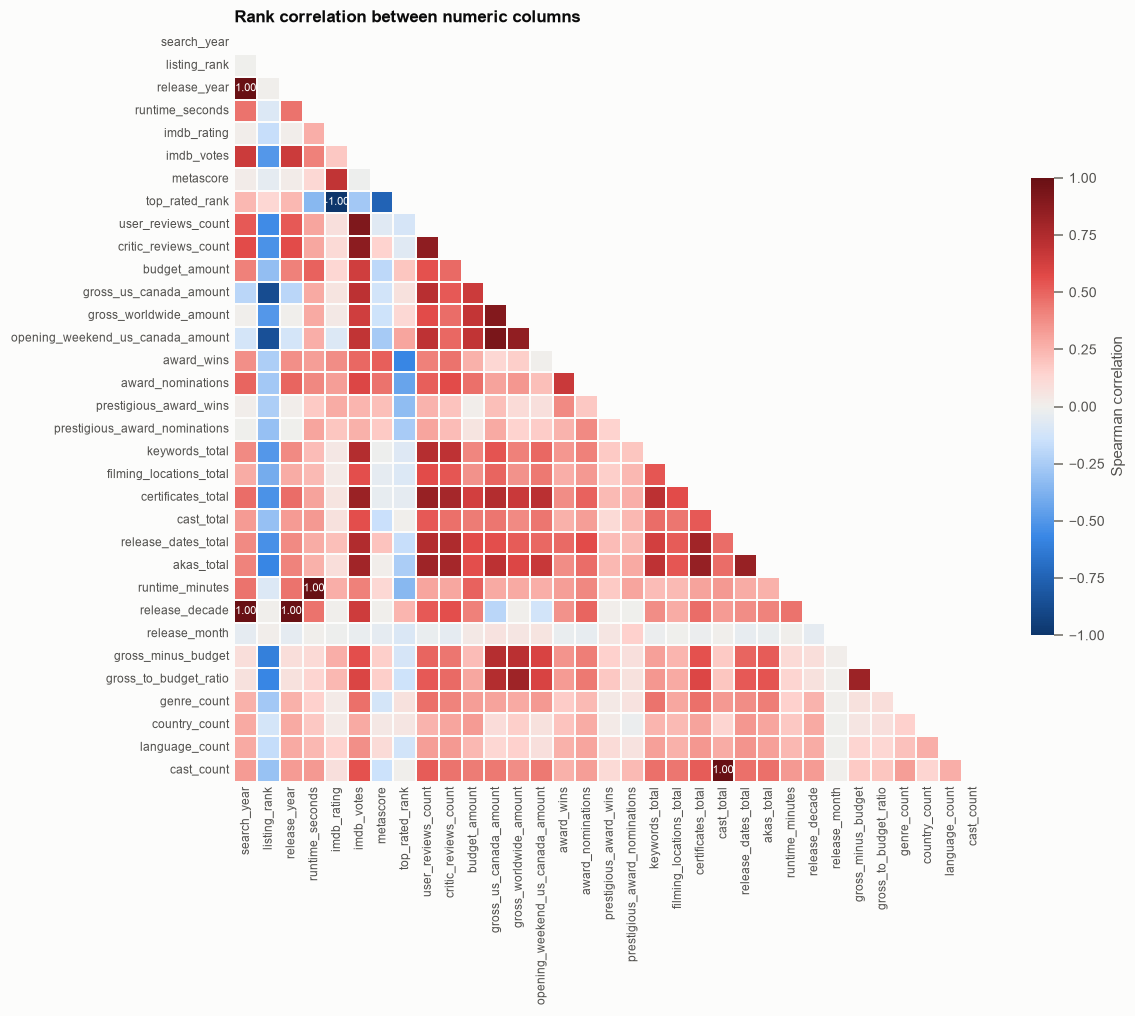

In [9]:
numeric = movies.select_dtypes(include=["number"]).astype(float)
numeric = numeric.loc[:, numeric.notna().sum() >= 1_000]
correlation = numeric.corr(method="spearman", min_periods=1_000)
labels = correlation.map(lambda r: f"{r:.2f}" if abs(r) >= 0.95 else "")
mask = np.triu(np.ones_like(correlation, dtype=bool))

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(correlation, mask=mask, cmap=BLUE_RED, vmin=-1, vmax=1, center=0, annot=labels, fmt="",
            annot_kws={"fontsize": 7}, linewidths=1, linecolor=SURFACE, square=True,
            cbar_kws={"shrink": 0.6, "label": "Spearman correlation"}, ax=ax)
ax.grid(False)
ax.tick_params(length=0, labelsize=8)
ax.set_title("Rank correlation between numeric columns")
plt.show()

## 5. Missing values

Missing values fall into three kinds, and each needs a different treatment:

- **Structural:** the value did not exist, like a Metascore before Metacritic or box office for old films. These stay missing.
- **Recorded as zero:** IMDb shows no awards, reviews or keywords. These columns already use 0, which is correct.
- **Recoverable:** another column holds the same information, such as the certificate from the US entries of `certificates_by_country`.

The `_ids` lists and the currency columns are left out of the chart because they are missing exactly when their partner column is.

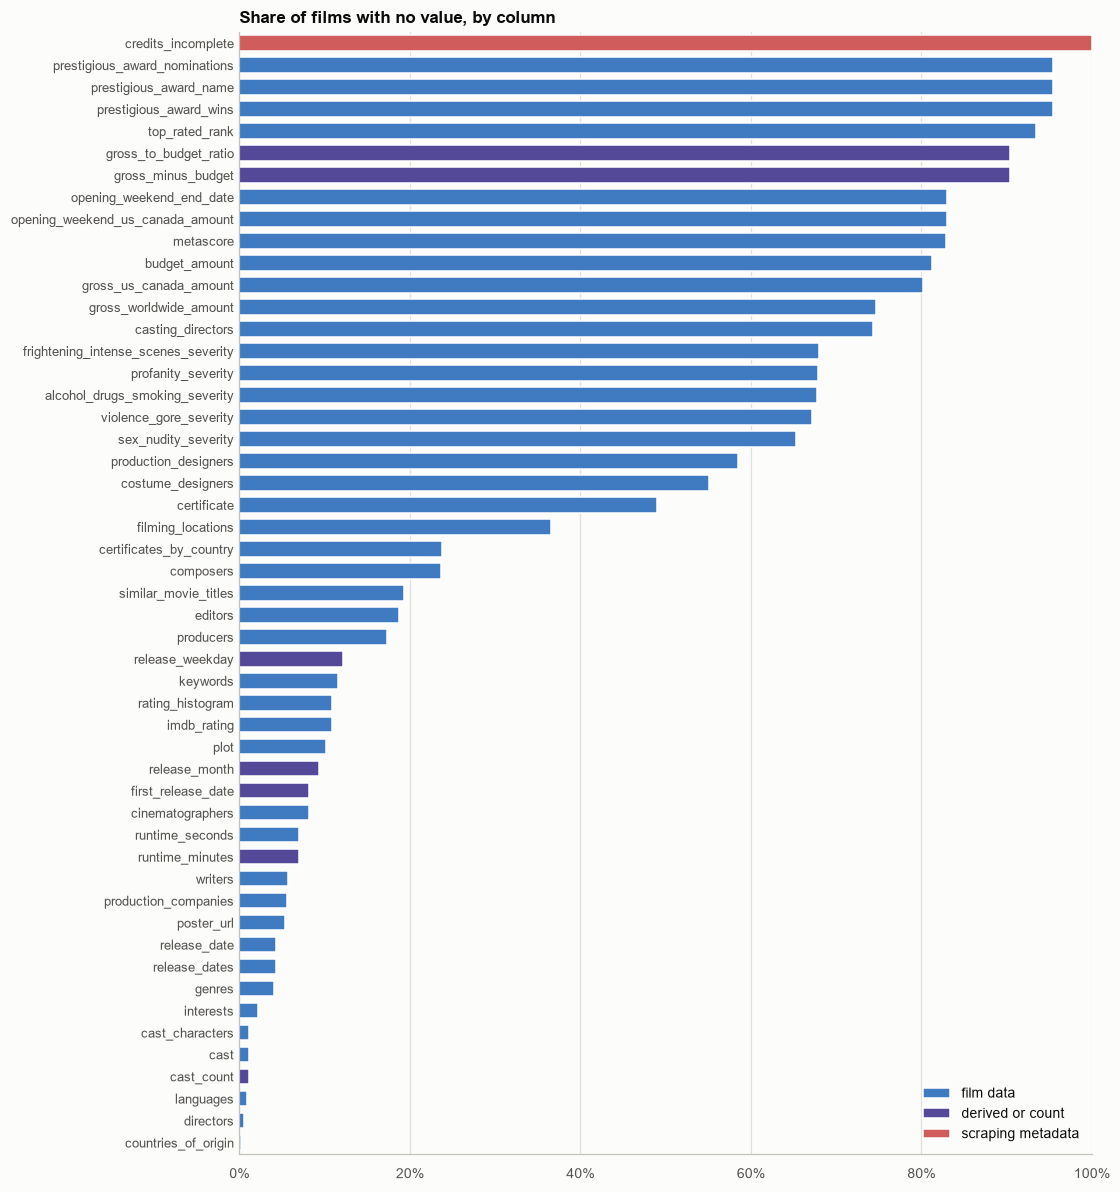

In [10]:
skip = [c for c in movies.columns if c.endswith("_ids") or c.endswith("_currency")] + ["release_date_precision", "release_date_country"]
missing = (
    inventory.drop(index=skip)
    .query("`missing %` > 0")
    .sort_values("missing %", ascending=False)
    .rename_axis("column").reset_index()
)

fig, ax = plt.subplots(figsize=(10, 0.24 * len(missing) + 1))
sns.barplot(data=missing, y="column", x="missing %", hue="role", hue_order=list(ROLE_COLORS), palette=ROLE_COLORS,
            dodge=False, width=0.7, ax=ax)
ax.xaxis.set_major_formatter(PercentFormatter(decimals=0))
ax.set(xlabel="", ylabel="", xlim=(0, 100))
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", length=0, labelsize=8.5)
ax.legend(title="", loc="lower right")
ax.set_title("Share of films with no value, by column")
plt.show()

Missingness by decade shows which gaps are structural. Box office, budgets, Metascores and parental guides are mostly missing for old films and much more complete for recent ones.

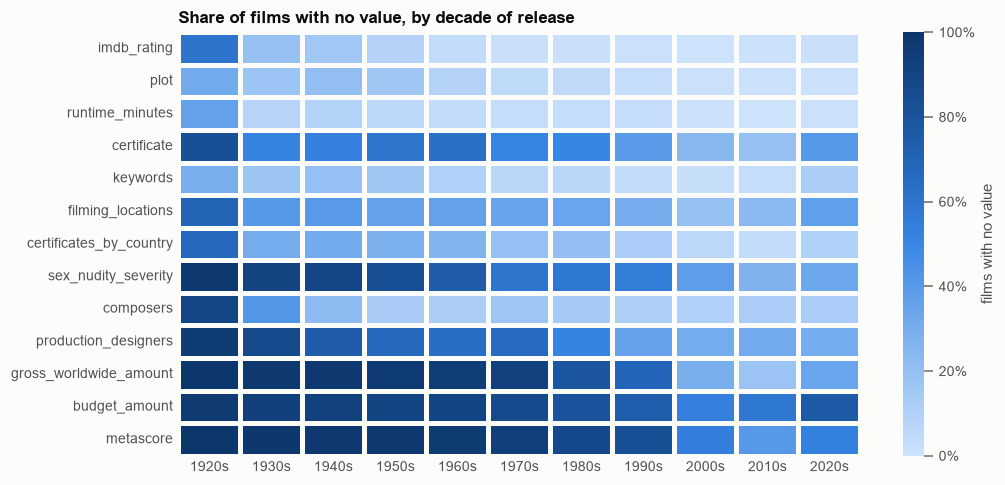

,1920s,1930s,1940s,1950s,1960s,1970s,1980s,1990s,2000s,2010s,2020s
imdb_rating,61,19,16,9,4,2,2,1,0,0,2
plot,32,17,21,16,9,5,5,3,1,0,0
runtime_minutes,36,8,10,6,4,3,3,3,1,0,1
certificate,83,52,53,60,63,52,51,39,24,19,40
keywords,30,17,20,16,11,6,7,4,3,3,12
filming_locations,70,40,40,36,37,35,34,30,19,23,38
certificates_by_country,67,30,31,29,26,20,20,13,6,4,11
sex_nudity_severity,98,91,89,84,75,60,59,55,38,27,33
composers,89,42,22,13,12,16,14,12,10,13,13
production_designers,95,86,74,67,64,66,52,36,31,32,30


In [11]:
DECADE_FIELDS = ["imdb_rating", "plot", "runtime_minutes", "certificate", "keywords", "filming_locations",
                 "certificates_by_country", "sex_nudity_severity", "composers", "production_designers",
                 "gross_worldwide_amount", "budget_amount", "metascore"]
by_decade = movies[DECADE_FIELDS].isna().groupby(movies["release_year"] // 10 * 10).mean().mul(100).T
by_decade.columns = [f"{int(decade)}s" for decade in by_decade.columns]

fig, ax = plt.subplots(figsize=(10, 5))
sns.heatmap(by_decade, cmap=BLUES, vmin=0, vmax=100, linewidths=2, linecolor=SURFACE,
            cbar_kws={"format": PercentFormatter(decimals=0), "label": "films with no value"}, ax=ax)
ax.grid(False)
ax.tick_params(length=0)
ax.set(xlabel="", ylabel="")
ax.set_title("Share of films with no value, by decade of release")
plt.show()
display(by_decade.round(0).astype(int))

Counts already use 0 for "none". For example, a film with no votes has `imdb_votes` = 0, and its rating is missing:

In [12]:
zero_counts = ["imdb_votes", "user_reviews_count", "critic_reviews_count", "award_wins", "award_nominations", "keywords_total"]
display(pd.DataFrame({
    "missing": movies[zero_counts].isna().sum(),
    "zero": (movies[zero_counts] == 0).sum(),
}))
print(pd.crosstab(movies["imdb_votes"].eq(0).rename("no votes"), movies["imdb_rating"].isna().rename("rating missing")))

,missing,zero
imdb_votes,1,11619
user_reviews_count,0,27108
critic_reviews_count,0,35845
award_wins,0,78203
award_nominations,0,75989
keywords_total,0,12458


rating missing  False  True 
no votes                    
False           95379      0
True                0  11619


## 6. Types and memory

In memory the table takes almost a gigabyte, nearly all of it text. Types can be tightened in three ways:

- **Small integers** (years, runtimes, Metascores, ranks) fit in `Int16` instead of `Int64`.
- **Ratings** fit in `Float32`.
- **Repeated labels** (certificates, severities, currencies, statuses, weekdays) become `category` columns.

The estimate below applies exactly those changes; it leaves the lists and free text alone. The real tightening comes last, in section 25, once the cleanup is done.

Total: 634 MB now, 594 MB with tightened types (49 columns change type).


,now (MB),tightened (MB),type now,tightened type
release_date_country,1.91,0.22,str,category
production_status,1.71,0.11,str,category
release_info_complete,1.71,0.11,str,category
release_weekday,1.54,0.11,str,category
title_type,1.39,0.11,str,category
similar_movies_status,1.39,0.11,str,category
release_date_precision,1.19,0.11,str,category
certificate,1.14,0.11,str,category
violence_gore_severity,1.06,0.11,str,category
frightening_intense_scenes_severity,1.06,0.11,str,category


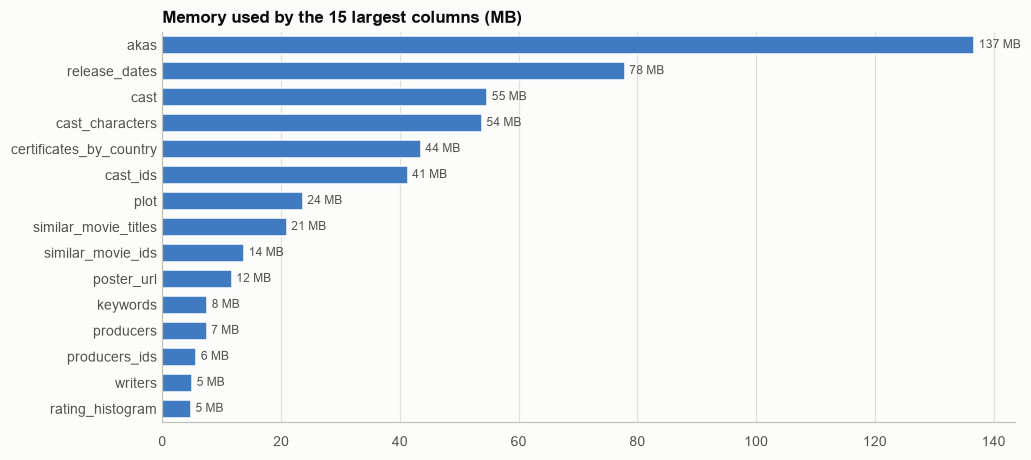

In [13]:
def smallest_int(series):
    """The smallest nullable integer type that holds every value of the series."""
    for kind in ("Int8", "Int16", "Int32"):
        info = np.iinfo(kind.lower())
        if series.dropna().between(info.min, info.max).all():
            return kind
    return "Int64"


tightened = movies.copy()
for column in tightened.columns:
    values = tightened[column]
    if str(values.dtype) == "Int64":
        tightened[column] = values.astype(smallest_int(values))
    elif str(values.dtype) == "Float64":
        tightened[column] = values.astype("Float32")
    elif column not in JSON_COLUMNS and values.dtype.kind == "O" and values.nunique() <= 1_000:
        tightened[column] = values.astype("category")

memory = pd.DataFrame({
    "now (MB)": movies.memory_usage(deep=True, index=False) / 1e6,
    "tightened (MB)": tightened.memory_usage(deep=True, index=False) / 1e6,
    "type now": movies.dtypes.astype(str),
    "tightened type": tightened.dtypes.astype(str),
})
del tightened
changed = memory[memory["type now"] != memory["tightened type"]]
print(f"Total: {memory['now (MB)'].sum():,.0f} MB now, {memory['tightened (MB)'].sum():,.0f} MB with tightened types "
      f"({len(changed)} columns change type).")
display(changed.round(2).sort_values("now (MB)", ascending=False))

largest = memory["now (MB)"].sort_values(ascending=False).head(15)
fig, ax = plt.subplots(figsize=(10, 4.6))
sns.barplot(x=largest.values, y=largest.index, color=BLUE, width=0.7, ax=ax)
ax.bar_label(ax.containers[0], fmt="{:,.0f} MB", padding=3, color=INK_2, fontsize=8)
ax.set(xlabel="", ylabel="")
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", length=0)
ax.set_title("Memory used by the 15 largest columns (MB)")
plt.show()

## 7. The certificate (age rating)

`certificate` is the rating IMDb shows on a film's page. It mixes several US rating systems, plus a few labels that belong to none of them:

- **Current MPA ratings:** G, PG, PG-13, R, NC-17.
- **Older MPA ratings:** GP and M (both became PG), M/PG, and X (replaced by NC-17).
- **Production Code era (before 1968):** Approved and Passed. They say a film was cleared for release, not who may watch it.
- **US TV ratings:** TV-Y, TV-Y7, TV-G, TV-PG, TV-14, TV-MA.
- **Streaming labels:** 13+, 16+, 18+.
- **Video-game ratings and one-offs:** E, E10+ and T come from video games; `(Banned)`, `Open`, `MA-17` and `12` are isolated labels.
- **No rating:** Not Rated and Unrated.

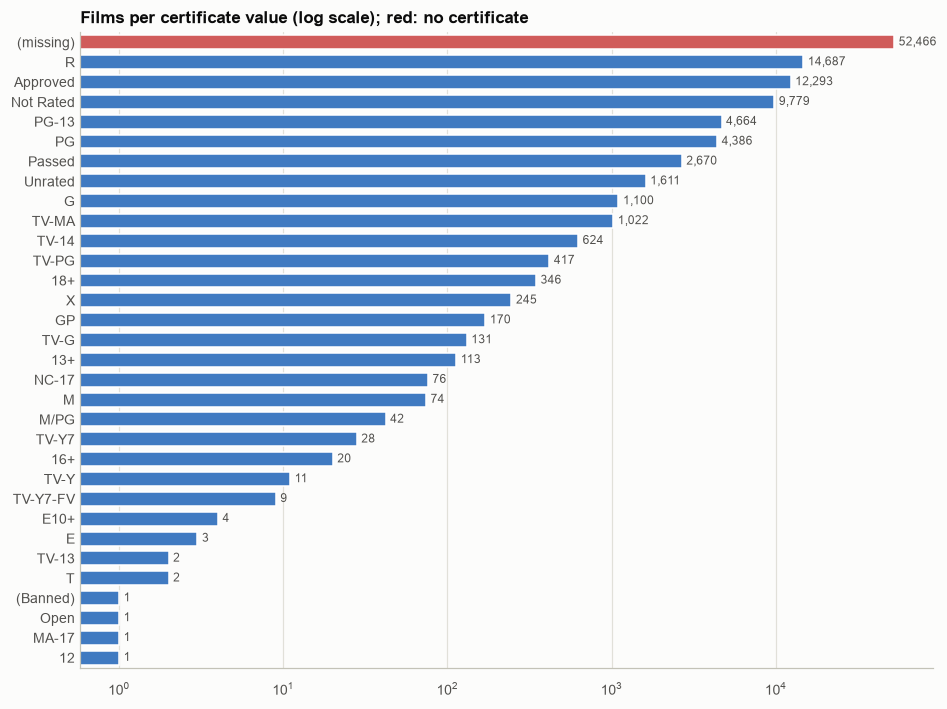

In [14]:
counts = movies["certificate"].fillna("(missing)").value_counts()
fig, ax = plt.subplots(figsize=(10, 7.5))
sns.barplot(x=counts.values, y=counts.index, hue=counts.index, legend=False, width=0.7, ax=ax,
            palette=[RED if label == "(missing)" else BLUE for label in counts.index])
for container in ax.containers:
    ax.bar_label(container, fmt="{:,.0f}", padding=3, color=INK_2, fontsize=8)
ax.set(xlabel="", ylabel="", xscale="log")
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", length=0)
ax.set_title("Films per certificate value (log scale); red: no certificate")
plt.show()

`certificates_by_country` holds every country's ratings, including the United States. Its first US rating agrees with `certificate` for most films. The disagreements are mostly expected: Approved against Passed, or a theatrical rating against a later TV rating. It can fill the gap for films without a `certificate`.

In [15]:
us_ratings = parsed["certificates_by_country"].map(
    lambda certificates: [entry["rating"] for entry in certificates if entry["country"] == "United States"], na_action="ignore")
first_us = us_ratings.map(lambda ratings: ratings[0] if ratings else None, na_action="ignore")
both = movies["certificate"].notna() & first_us.notna()
print(f"Films with a US entry: {first_us.notna().sum():,}. Where both exist, they agree for "
      f"{(movies.loc[both, 'certificate'] == first_us[both]).mean():.1%}.")
print(f"A US entry could fill the certificate of {(movies['certificate'].isna() & first_us.notna()).sum():,} films.")
pairs = pd.DataFrame({"certificate": movies.loc[both, "certificate"], "first US entry": first_us[both]})
display(pairs[pairs["certificate"] != pairs["first US entry"]].value_counts().head(10).rename("films").reset_index())

Films with a US entry: 53,983. Where both exist, they agree for 83.9%.
A US entry could fill the certificate of 94 films.


,certificate,first US entry,films
0,Approved,Passed,4238
1,R,TV-14,812
2,Approved,Not Rated,466
3,R,TV-MA,370
4,Approved,TV-PG,367
5,PG,TV-PG,328
6,PG-13,TV-14,322
7,Approved,TV-G,169
8,PG-13,TV-PG,113
9,PG,TV-G,94


## 8. Categorical fields

The repeated labels are mostly clean. Two need a decision:

- **`languages`** contains `None` for films without spoken language (silent films). It is IMDb's placeholder, not a language.
- **`countries_of_origin`** uses historical names: West Germany, Soviet Union, Yugoslavia, Czechoslovakia. They are correct for their time and stay as they are.

The money columns use ISO 4217 currency codes such as USD, never symbols. Amounts stay in their own currency: converting them would need historical exchange rates and inflation data.

In [16]:
def items(column):
    return parsed[column].explode().dropna()


HISTORICAL = {"West Germany", "East Germany", "Soviet Union", "Yugoslavia", "Czechoslovakia",
              "Federal Republic of Yugoslavia", "Serbia and Montenegro"}
display(pd.DataFrame([
    {"field": "genres", "distinct": items("genres").nunique(), "note": "25 IMDb genres"},
    {"field": "interests", "distinct": items("interests").nunique(), "note": "themes, sub-genres and franchises"},
    {"field": "countries_of_origin", "distinct": items("countries_of_origin").nunique(),
     "note": f"{items('countries_of_origin').isin(HISTORICAL).sum():,} mentions of historical countries"},
    {"field": "languages", "distinct": items("languages").nunique(),
     "note": f"'None' (no spoken language) on {(items('languages') == 'None').sum():,} films"},
    {"field": "production_companies", "distinct": items("production_companies").nunique(), "note": "free-form company names"},
    {"field": "budget_currency", "distinct": movies["budget_currency"].nunique(), "note": "ISO 4217 codes, kept without conversion"},
    {"field": "prestigious_award_name", "distinct": movies["prestigious_award_name"].nunique(), "note": "Oscar, BAFTA, Emmy, ..."},
]))

,field,distinct,note
0,genres,25,25 IMDb genres
1,interests,286,"themes, sub-genres and franchises"
2,countries_of_origin,194,"5,560 mentions of historical countries"
3,languages,275,"'None' (no spoken language) on 8,911 films"
4,production_companies,51223,free-form company names
5,budget_currency,69,"ISO 4217 codes, kept without conversion"
6,prestigious_award_name,18,"Oscar, BAFTA, Emmy, ..."


## 9. Numeric distributions and outliers

The red lines mark values worth a closer look. A feature film runs at least 40 minutes by the usual definition (AMPAS, BFI), and a budget under 1,000 USD is almost certainly a data-entry error.

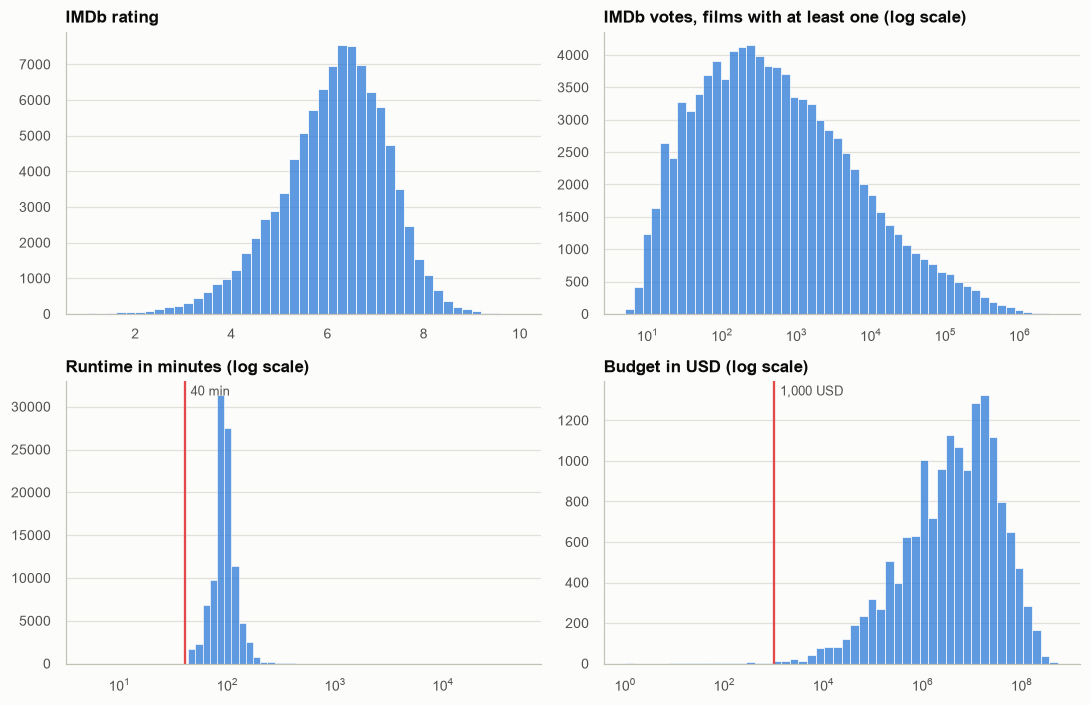

In [17]:
fig, axes = plt.subplots(2, 2, figsize=(10, 6.5))
sns.histplot(movies["imdb_rating"].dropna().astype(float), bins=np.arange(1, 10.2, 0.2), color=BLUE, ax=axes[0, 0])
axes[0, 0].set_title("IMDb rating")
sns.histplot(movies.loc[movies["imdb_votes"] > 0, "imdb_votes"].astype(float), log_scale=True, bins=50, color=BLUE, ax=axes[0, 1])
axes[0, 1].set_title("IMDb votes, films with at least one (log scale)")
sns.histplot(movies["runtime_minutes"].dropna().astype(float), log_scale=True, bins=60, color=BLUE, ax=axes[1, 0])
axes[1, 0].axvline(40, color=RED, linewidth=1.5)
axes[1, 0].annotate("40 min", (40, 0.95), xycoords=("data", "axes fraction"), xytext=(4, 0), textcoords="offset points", color=INK_2, fontsize=8.5)
axes[1, 0].set_title("Runtime in minutes (log scale)")
usd_budget = movies.loc[movies["budget_currency"] == "USD", "budget_amount"]
sns.histplot(usd_budget[usd_budget > 0].astype(float), log_scale=True, bins=50, color=BLUE, ax=axes[1, 1])
axes[1, 1].axvline(1_000, color=RED, linewidth=1.5)
axes[1, 1].annotate("1,000 USD", (1_000, 0.95), xycoords=("data", "axes fraction"), xytext=(4, 0), textcoords="offset points", color=INK_2, fontsize=8.5)
axes[1, 1].set_title("Budget in USD (log scale)")
for ax in axes.flat:
    ax.set(xlabel="", ylabel="")
    ax.grid(axis="x", visible=False)
fig.tight_layout()
plt.show()

In [18]:
runtime = movies["runtime_minutes"]
checks = {
    "runtime under 40 minutes": runtime < 40,
    "runtime over 400 minutes": runtime > 400,
    "budget under 1,000 USD": (movies["budget_currency"] == "USD") & (movies["budget_amount"] < 1_000),
    "opening weekend above total US gross": movies["opening_weekend_us_canada_amount"] > movies["gross_us_canada_amount"],
    "gross more than 100x the budget": movies["gross_to_budget_ratio"] > 100,
    "not released (abandoned, in production, ...)": movies["production_status"].fillna("unknown") != "released",
    "US gross not in USD": movies["gross_us_canada_currency"].notna() & (movies["gross_us_canada_currency"] != "USD"),
}
outliers = pd.DataFrame([
    {"check": name, "films": int(flag.fillna(False).sum()),
     "examples": movies.loc[flag.fillna(False).to_numpy(), "title"].head(3).tolist()}
    for name, flag in checks.items()
])
display(outliers)
display(movies.loc[runtime > 400, ["imdb_id", "title", "release_year", "runtime_minutes"]].sort_values("runtime_minutes", ascending=False).head(6))

,check,films,examples
0,runtime under 40 minutes,12,"[Sol, sommer og studiner, Baptême du Belgenland par S.E...."
1,runtime over 400 minutes,25,"[A Mosca cieca, The Wheel, L'enfant roi]"
2,"budget under 1,000 USD",54,"[A Pirate for a Day, Chang: A Drama of the Wilderness, T..."
3,opening weekend above total US gross,67,"[The 400 Blows, Jules and Jim, The Soft Skin]"
4,gross more than 100x the budget,33,"[Snow White and the Seven Dwarfs, Gone with the Wind, Ba..."
5,"not released (abandoned, in production, ...)",82,"[L'école des femmes, Kaleidoscope, L'uomo di Corleone]"
6,US gross not in USD,5,"[My American Wife, Forbidden Paradise, The Fair Co-Ed]"


,imdb_id,title,release_year,runtime_minutes
92659,tt8273150,Logistics,2012,51420.0
67501,tt0284020,The Cure for Insomnia,1987,5220.0
50492,tt0342707,The Longest Most Meaningless Movie in the World,1970,2880.0
91816,tt36048385,11-22-63: A Novel,2011,1840.0
8026,tt0165127,Burning of the Red Lotus Temple,1928,1620.0
47266,tt0179184,****,1967,1500.0


Long runtimes are mostly genuine: serials, multi-part films and experimental works such as *Logistics* (2012), a 35-day film. They stay. Tiny budgets, on the other hand, are entry errors that turn `gross_to_budget_ratio` into numbers like 39,622.

## 10. Text quality

Every string in the text fields is checked, including list elements and the text inside records: about 19 million strings. A fast pre-filter keeps only the strings that contain a non-ASCII character, edge or double spaces, or an `&`. The detailed checks then run on those.

| Issue | Example | Typical cause |
| --- | --- | --- |
| Leading or trailing whitespace, repeated spaces | `'Silvino Salas 'Sal' '` | Data entry |
| Non-standard whitespace | No-break space, ideographic space (U+3000), line breaks | Copy and paste, CJK typography |
| Invisible format characters | Zero-width space, soft hyphen, BOM, direction marks | Copy and paste |
| Zero-width joiners | ZWNJ in Persian titles | **Often correct**: part of the spelling in Persian and Indic scripts |
| Control characters | U+0082 | Left over from broken encodings |
| HTML entities | `&#1052;&#1086;&#1089;...` | Escaped text stored as is |
| Mojibake | `estÃ¡` instead of `está` | UTF-8 read as Windows-1252 |
| Changes under NFKC | `8½`, `Dª`, full-width brackets | **Usually correct**: compatibility forms used on purpose |

The patterns are built from code points with `char_class`, so the notebook's source never contains invisible characters itself.

18,859,231 strings checked; 1,025,049 passed the pre-filter.
Issues found nowhere: not NFC


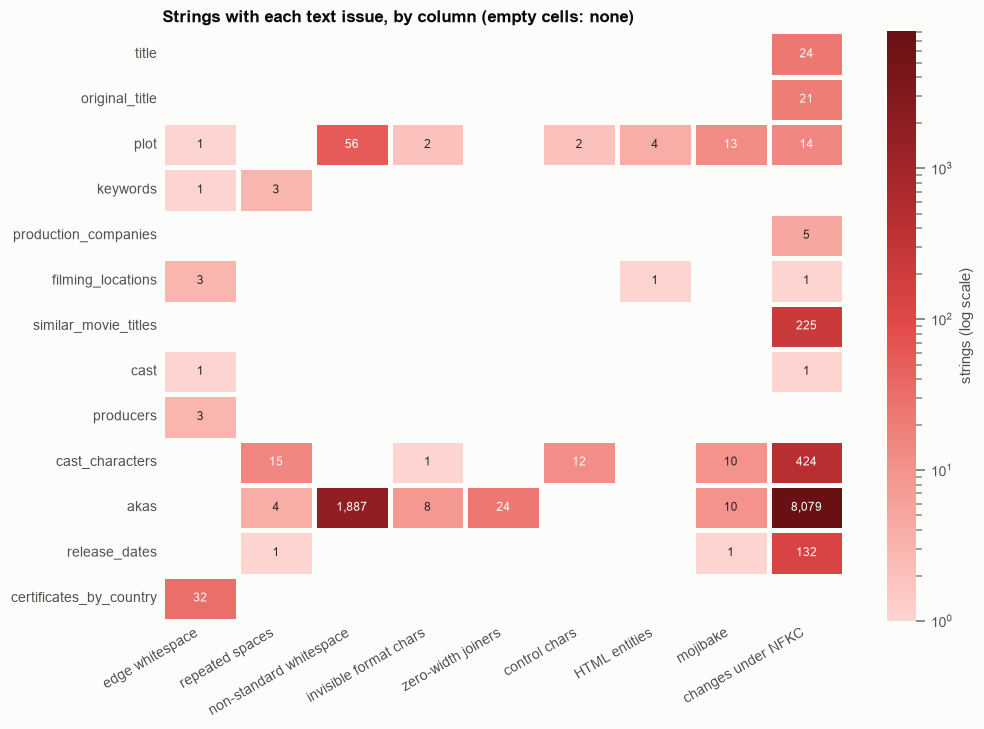

In [19]:
def char_class(*points):
    """A regex character class from code points and (first, last) ranges."""
    parts = []
    for point in points:
        first, last = point if isinstance(point, tuple) else (point, point)
        parts.append(re.escape(chr(first)) + ("-" + re.escape(chr(last)) if last != first else ""))
    return "[" + "".join(parts) + "]"


# No-break, ogham, typographic and ideographic spaces, tabs and line breaks
ODD_SPACES = char_class(0x00A0, 0x1680, (0x2000, 0x200A), 0x202F, 0x205F, 0x3000, (0x09, 0x0D))
# Soft hyphen, Mongolian vowel separator, zero-width space, direction marks and isolates, separators, word joiners, BOM
INVISIBLE_CHARS = char_class(0x00AD, 0x180E, 0x200B, 0x200E, 0x200F, 0x2028, 0x2029, (0x202A, 0x202E),
                             (0x2060, 0x2064), (0x2066, 0x2069), 0xFEFF)
JOINERS = char_class(0x200C, 0x200D)  # zero-width non-joiner and joiner
CONTROL_CHARS = char_class((0x00, 0x08), 0x0B, 0x0C, (0x0E, 0x1F), (0x7F, 0x9F))
MOJIBAKE_PATTERN = "[ÃÂ][\x80-\xbf]|â€|Å[\x80-\xbfŒœŠšŸŽž‘’‚“”„†‡•…‰‹›€™]"
ENTITY_PATTERN = r"&(?:[a-zA-Z]{2,8}|#\d{2,5}|#x[0-9a-fA-F]{2,4});"
SUSPECT_PATTERN = r"[^\x20-\x7e]|^\s|\s$|\s\s|&"

SCALAR_TEXT = ["title", "original_title", "plot", "certificate", "prestigious_award_name", "release_date_country"]
LIST_TEXT = ["genres", "interests", "keywords", "countries_of_origin", "languages", "production_companies",
             "filming_locations", "similar_movie_titles", *CREDIT_GROUPS, "cast_characters",
             "akas", "release_dates", "certificates_by_country"]


def strings(frame, lists, scalar_columns, list_columns):
    """Every string in the given columns: plain values, list elements, nested list elements and record fields."""
    parts = [frame[column].dropna().astype(str).rename("text").to_frame().assign(column=column) for column in scalar_columns]
    for column in list_columns:
        values = lists[column].explode().dropna()
        if len(values) and isinstance(values.iloc[0], list):
            values = values.explode().dropna()
        elif len(values) and isinstance(values.iloc[0], dict):
            values = values.map(lambda record: [v for v in record.values() if isinstance(v, str)]).explode().dropna()
        parts.append(values.astype(str).rename("text").to_frame().assign(column=column))
    return pd.concat(parts, ignore_index=True)


def text_issues(texts):
    """Boolean table: one row per suspect string, one column per issue."""
    s = texts["text"]
    return pd.DataFrame({
        "edge whitespace": s != s.str.strip(),
        "repeated spaces": s.str.contains("  ", regex=False),
        "non-standard whitespace": s.str.contains(ODD_SPACES),
        "invisible format chars": s.str.contains(INVISIBLE_CHARS),
        "zero-width joiners": s.str.contains(JOINERS),
        "control chars": s.str.contains(CONTROL_CHARS),
        "HTML entities": s.str.contains(ENTITY_PATTERN),
        "mojibake": s.str.contains(MOJIBAKE_PATTERN),
        "not NFC": ~s.map(lambda value: unicodedata.is_normalized("NFC", value)),
        "changes under NFKC": ~s.map(lambda value: unicodedata.is_normalized("NFKC", value)),
    })


texts = strings(movies, parsed, SCALAR_TEXT, LIST_TEXT)
suspect = texts[texts["text"].str.contains(SUSPECT_PATTERN, regex=True)]
issues = text_issues(suspect)
audit = issues.groupby(suspect["column"]).sum().reindex(SCALAR_TEXT + LIST_TEXT, fill_value=0)
print(f"{len(texts):,} strings checked; {len(suspect):,} passed the pre-filter.")
del texts
shown = audit.loc[audit.sum(axis=1) > 0, audit.sum() > 0]
print("Issues found nowhere:", ", ".join(audit.columns[audit.sum() == 0]) or "none")

fig, ax = plt.subplots(figsize=(10, 0.42 * len(shown) + 1.5))
sns.heatmap(shown, mask=shown == 0, cmap=REDS, norm=LogNorm(vmin=1, vmax=shown.to_numpy().max()),
            annot=True, fmt=",", annot_kws={"fontsize": 8}, linewidths=2, linecolor=SURFACE,
            cbar_kws={"label": "strings (log scale)"}, ax=ax)
ax.grid(False)
ax.tick_params(length=0)
ax.set(xlabel="", ylabel="")
plt.setp(ax.get_xticklabels(), rotation=30, ha="right")
ax.set_title("Strings with each text issue, by column (empty cells: none)")
plt.show()

Mojibake can often be undone by re-encoding the text as Windows-1252 (or Latin-1) and decoding it as UTF-8. That works only when the text really is double-encoded. Some flagged strings are correct: *Â bakudan* is the romanised Japanese title of *Ah, Bomb!* (1964). Re-decoding separates the two cases:

In [20]:
def redecode(text):
    """Undo one round of UTF-8 read as Windows-1252 or Latin-1; None if the text was not double-encoded."""
    for codec in ("cp1252", "latin-1"):
        try:
            return text.encode(codec).decode("utf-8")
        except UnicodeError:
            continue
    return None


candidates = suspect.loc[issues["mojibake"], ["column", "text"]].drop_duplicates("text")
candidates["re-decoded"] = candidates["text"].map(redecode)
print(f"{len(candidates)} distinct flagged strings: {candidates['re-decoded'].notna().sum()} decode cleanly, "
      f"{candidates['re-decoded'].isna().sum()} do not.")
display(pd.concat([candidates[candidates["re-decoded"].notna()].head(8), candidates[candidates["re-decoded"].isna()].head(4)]))
del suspect, issues

34 distinct flagged strings: 29 decode cleanly, 5 do not.


,column,text,re-decoded
218958,plot,"Gabrielle (Helene Hallier), an ambitious but innocent wo...","Gabrielle (Helene Hallier), an ambitious but innocent wo..."
258056,plot,Valeriano Mendoza (Narciso Busquets) se adueÃ±a a la mal...,Valeriano Mendoza (Narciso Busquets) se adueña a la mala...
259273,plot,La pasiÃ³n y el odio gobiernan una pequeÃ±a villa mexicana.,La pasión y el odio gobiernan una pequeña villa mexicana.
261605,plot,Esta es la historia de un experto en gallos de peleas y ...,Esta es la historia de un experto en gallos de peleas y ...
261920,plot,"En la ciudad de Aguaprieta, dos caballos son parte del m...","En la ciudad de Aguaprieta, dos caballos son parte del m..."
262033,plot,"Protagonizada por Claudia Islas, la tragedia de la muert...","Protagonizada por Claudia Islas, la tragedia de la muert..."
262777,plot,Nace el hijo de LÃ¡zaro y crece con todo el cariÃ±o de l...,Nace el hijo de Lázaro y crece con todo el cariño de las...
274463,plot,Lamberto Quintero es asesinado y su hijo se propone veng...,Lamberto Quintero es asesinado y su hijo se propone veng...
243534,plot,Nadie imaginó ver bailar twist a estas grandes figuras. ...,NaN
246500,plot,"Shola aur Shabnam explores the story of childhood love, ...",NaN


HTML entities decode with the standard library: `html.unescape("Moscow, &#1052;&#1086;&#1089;&#1082;&#1074;&#1072;")` gives `'Moscow, Москва'`.

## 11. The plot text

`plot` is the field most useful for language processing: topic modelling, search, similarity. Its length varies a lot, and some plots are cut off with `...`, duplicated across films, or not in English.

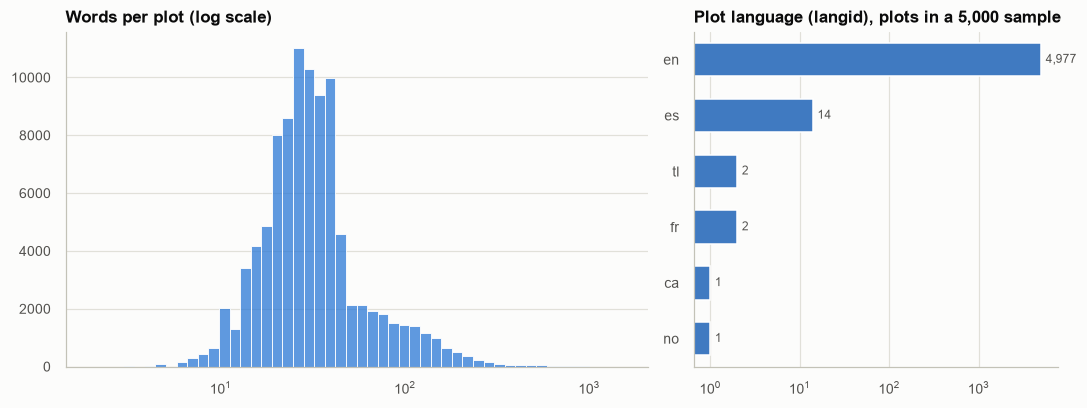

96,045 plots; median 30 words (min 2, max 1,490). 786 end with '...', 274 are shared by more than one film, and an estimated 0.5% are not in English.


,title,release_year,plot
19065,Buck Rogers,1939,A 20th Century pilot named Buck Rogers and his young fri...
33308,Planet Outlaws,1953,A 20th Century pilot named Buck Rogers and his young fri...
90202,Raavan,2010,A bandit leader kidnaps the wife of the policeman who ki...
90810,Raavanan,2010,A bandit leader kidnaps the wife of the policeman who ki...
11641,Les amours de minuit,1931,A bank employee who stole money at work falls in the han...
11898,Mitternachtsliebe,1931,A bank employee who stole money at work falls in the han...


In [21]:
plots = movies["plot"].dropna()
words = plots.str.split().str.len()
truncated = plots.str.rstrip().str.endswith(("...", "…"))
duplicated = plots.duplicated(keep=False)
sample = plots.sample(5_000, random_state=0)
languages = sample.map(lambda text: langid.classify(text)[0]).value_counts()

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), gridspec_kw={"width_ratios": [1.6, 1]})
sns.histplot(words, log_scale=True, bins=50, color=BLUE, ax=axes[0])
axes[0].set(xlabel="", ylabel="")
axes[0].grid(axis="x", visible=False)
axes[0].set_title("Words per plot (log scale)")
top_languages = languages.head(6)
sns.barplot(x=top_languages.values, y=top_languages.index, color=BLUE, width=0.6, ax=axes[1])
axes[1].bar_label(axes[1].containers[0], fmt="{:,.0f}", padding=3, color=INK_2, fontsize=8)
axes[1].set(xlabel="", ylabel="", xscale="log")
axes[1].grid(axis="y", visible=False)
axes[1].set_title("Plot language (langid), plots in a 5,000 sample")
fig.tight_layout()
plt.show()

print(f"{len(plots):,} plots; median {words.median():.0f} words (min {words.min()}, max {words.max():,}). "
      f"{truncated.sum():,} end with '...', {duplicated.sum():,} are shared by more than one film, "
      f"and an estimated {1 - languages.get('en', 0) / languages.sum():.1%} are not in English.")
display(movies.loc[plots[duplicated].index, ["title", "release_year", "plot"]].sort_values("plot").head(6))

## 12. Findings

- **Structure.** 24 columns can go:
  - 7 describe the scraping run, not the films.
  - 4 hold a single value.
  - 13 can be recomputed exactly from other columns: the runtime in seconds, the decade, the release month and weekday, seven list counts and totals, gross minus budget, and the gross-to-budget ratio.
- **Duplicated facts inside the lists.** The AKA lists repeat `original_title` in an "original title" row, `interests` repeats the genre names, and `filming_locations` never holds more than one place.
- **Missing values.** Most gaps are structural and depend on the era: box office, budgets, Metascores, parental guides, crew roles. Counts already use 0 for "none". The certificate is missing for 49% of films, and the US entries of `certificates_by_country` can fill some of them.
- **Types.** Every number is a 64-bit type and every label is free text. Most of the memory is JSON text: the AKAs alone take about 250 MB.
- **Certificate.** 31 labels from six rating systems, plus one-offs, need an age group.
- **Categories.** `None` is a placeholder language on 8,911 films. Historical countries are correct for their time. Currencies are ISO codes; budgets use 69 of them.
- **Outliers.** Extreme runtimes are mostly genuine; 54 budgets under 1,000 USD are not. 82 films were never released and 12 run under 40 minutes.
- **Text.**
  - Every string is already in NFC form. The real problems are rare: broken encodings, HTML entities, control characters, invisible characters and odd whitespace.
  - About 8,900 strings use compatibility characters on purpose (`½`, `ª`, full-width brackets), so NFKC is only safe for search keys.
  - Some flagged strings are correct as they are: ZWNJ in Persian titles, and *Â bakudan*.
  - Several fields spell the same value with different case: release-date notes, certificate notes and ratings, production companies, filming locations and character names.
- **Plot.** The median plot has 30 words. 786 plots are cut off with `...`, 274 are shared by re-edits and language versions of the same film, and about 0.5% are not in English, mostly Spanish.

## 13. Cleanup plan

| Section | Step |
| --- | --- |
| 14 | Remove the 94 films that are not released feature films: 82 never released and 12 shorter than 40 minutes |
| 15 | Remove 25 columns: 7 with scraping metadata, 5 with a single value and 13 that can be recomputed |
| 16 | Profile the remaining columns by type, to confirm which ones hold a fixed set of values |
| 17 | Clean every string, inside JSON too: broken encodings, HTML entities, NFC, invisible and control characters, whitespace; drop entries left empty |
| 18 | Unify spellings that differ only in case, to the most frequent one |
| 19 | Consolidate: the original-title row out of `akas`, genre names out of `interests`, one `filming_location`, credits and similar movies as records, `None` language to `silent_movie` |
| 20 | Certificate: fill from US theatrical ratings, add `age_group` and `min_age` |
| 21 | Release date: the earliest known one, with its precision and country |
| 22 | Money, awards and missing values: invalid budgets, opening weekend in USD, prestigious-award counts |
| 23 | Plot: language, truncation flag, word count and lemmas |
| 24 | A search key for titles |
| 25 | Optimize the types, last, right before the export |
| 26 | Check the clean table against rules that must hold, and count the notable cases |
| 27 | Export the CSV, the Parquet file and the data dictionary |
| 28 | Compare before and after |

## 14. Remove the films that are not released feature films

The dataset covers released feature films. Films that were abandoned or never released, and films shorter than 40 minutes, fall outside it.

In [22]:
not_released = (movies["production_status"].fillna("unknown") != "released").to_numpy()
too_short = (movies["runtime_minutes"] < 40).fillna(False).to_numpy(dtype=bool)
removed = not_released | too_short
display(pd.DataFrame({"films": [int(not_released.sum()), int(too_short.sum()), int(removed.sum())]},
                     index=["never released", "shorter than 40 minutes", "removed"]))
clean = movies.loc[~removed].copy()
parsed = {column: values.loc[clean.index] for column, values in parsed.items()}
del movies_text
print(f"{len(clean):,} films remain.")

,films
never released,82
shorter than 40 minutes,12
removed,94


106,905 films remain.


## 15. Remove the columns that carry no information

Three groups of columns go:

- **Scraping metadata** describes the scraping run, not the films.
- **Single-value columns** never vary. `production_status` joins them now that only released films remain.
- **Recomputable columns** are exact functions of other columns (section 4).

In [23]:
DROPPED = {
    "scraping metadata": SCRAPING,
    "single value": ["title_type", "is_adult", "opening_weekend_us_canada_currency", "gross_comparison_currency",
                     "production_status"],
    "recomputable": ["runtime_seconds", "release_decade", "release_month", "release_weekday", "cast_count", "cast_total",
                     "genre_count", "country_count", "language_count", "release_dates_total", "akas_total",
                     "gross_minus_budget", "gross_to_budget_ratio"],
}
single_values = {column: clean[column].dropna().unique().tolist() for column in DROPPED["single value"]}
assert all(len(values) <= 1 for values in single_values.values()), single_values
clean = clean.drop(columns=[column for columns in DROPPED.values() for column in columns])
parsed.pop("credits_incomplete")
display(pd.DataFrame([{"reason": reason, "columns": len(columns), "names": ", ".join(columns)}
                      for reason, columns in DROPPED.items()]))
print(f"{movies.shape[1]} columns -> {clean.shape[1]}")
del movies

,reason,columns,names
0,scraping metadata,7,"search_year, listing_rank, listing_title, scraped_at, si..."
1,single value,5,"title_type, is_adult, opening_weekend_us_canada_currency..."
2,recomputable,13,"runtime_seconds, release_decade, release_month, release_..."


98 columns -> 73


## 16. Profile of the remaining columns

One line per column, by kind:

- **Numbers and dates:** their range.
- **Labels:** their values, most common first.
- **Free text:** its length.
- **Lists:** their length.
- **Records:** their fields.

The profile confirms which columns hold a fixed set of values: those become categories in section 25.

In [24]:
def readable(number):
    """Thousands separators for large numbers only, so that years read as years."""
    return f"{number:,.0f}" if abs(number) >= 10_000 else f"{float(number):g}"


def profile(column):
    values = clean[column]
    filled = round(float(values.notna().mean()) * 100, 1)
    if column in parsed:
        items = parsed[column].explode().dropna()
        if len(items) and isinstance(items.iloc[0], dict):
            return {"kind": "records", "filled %": filled, "distinct": None, "summary": "fields: " + ", ".join(items.iloc[0])}
        if len(items) and isinstance(items.iloc[0], list):
            return {"kind": "nested lists", "filled %": filled, "distinct": None, "summary": "parallel to cast"}
        numbers = len(items) and pd.api.types.is_number(items.iloc[0])
        return {"kind": "list", "filled %": filled, "distinct": None if numbers else items.astype(str).nunique(),
                "summary": f"up to {int(parsed[column].str.len().max())} per film"}
    if values.dtype.kind in "iuf":
        return {"kind": "number", "filled %": filled, "distinct": values.nunique(),
                "summary": f"{readable(values.min())} to {readable(values.max())} (median {readable(values.median())})"}
    if values.dtype.kind == "M":
        return {"kind": "date", "filled %": filled, "distinct": values.nunique(),
                "summary": f"{values.min():%Y-%m-%d} to {values.max():%Y-%m-%d}"}
    distinct = values.nunique()
    if distinct <= 300 and values.dropna().str.len().max() <= 60:
        top_values = values.value_counts().index[:8].tolist()
        more = f" ... ({distinct} values)" if distinct > 8 else ""
        return {"kind": "label", "filled %": filled, "distinct": distinct, "summary": ", ".join(top_values) + more}
    lengths = values.dropna().str.len()
    return {"kind": "text", "filled %": filled, "distinct": distinct,
            "summary": f"{lengths.min()} to {lengths.max():,} characters"}


column_profile = pd.DataFrame({column: profile(column) for column in clean.columns}).T
with pd.option_context("display.max_rows", 120, "display.max_colwidth", 100):
    display(column_profile)

,kind,filled %,distinct,summary
imdb_id,text,100.0,106905,9 to 10 characters
title,text,100.0,96979,1 to 196 characters
original_title,text,100.0,99148,1 to 196 characters
release_year,number,100.0,107,1920 to 2026 (median 1973)
plot,text,89.8,95811,"15 to 8,469 characters"
poster_url,text,94.6,101084,89 to 109 characters
certificate,label,51.0,31,"R, Approved, Not Rated, PG-13, PG, Passed, Unrated, G ... (31 values)"
release_date,text,95.7,30332,4 to 10 characters
release_date_precision,label,95.7,3,"day, month, year"
release_date_country,label,95.7,135,"United States, France, Italy, United Kingdom, India, Japan, Mexico, Germany ... (135 values)"


The profile adds three things to the plan:

- **Fixed value sets.** The label columns hold a fixed set of values: the certificate, the five parental-guide severities, the release-date precision and country, the currency codes and the prestigious award name. They become categories at the end. Titles, plots and URLs are free text and stay text.
- **Severities have an order:** none < mild < moderate < severe. They become ordered categories.
- **Lists of people and similar movies are parallel lists.** Names, IDs and characters only make sense together, which is why section 19 turns them into records.

## 17. Clean every string

Every string goes through the same steps, including the elements of lists and the text fields of records:

1. **HTML entities** become the characters they stand for.
2. **Broken encodings are repaired.** A few strings that no tool can repair are fixed by hand (`MANUAL_FIXES`). ftfy then repairs the rest, but only strings that match the broken-encoding pattern: on correct text it can do harm, for example turning *Â bakudan* into " bakudan" or garbling Cyrillic titles.
3. **Unicode NFC** composes accents into single characters, which loses nothing. NFKC is kept for the search key (section 24).
4. **Invisible and control characters are removed.** Zero-width joiners are kept only inside Arabic-script and Indic words, where they are part of the spelling.
5. **Whitespace:** every kind of space, tab or line break becomes one space, and edges are trimmed.

Entries left empty are dropped. Lists of labels lose repeated entries, but lists of people keep every position: a repeated name there belongs to a different person with the same name.

In [25]:
MANUAL_FIXES = {  # broken beyond automatic repair; the right text is clear from context
    "MelquÃ\x8dÂades": "Melquíades",
    "Malgo\x9cka": "Malgośka",        # Windows-1250 byte for ś, which ftfy would read as œ
    "FaÃfffÃf'Ã'Â¯d": "Faïd",
    'Ã¢ÂEURÂ"': "—",                  # an em dash encoded three times
    "â€TM": "’",                      # an apostrophe whose ™ byte was written as "TM"
}
NEEDS_WORK = re.compile(SUSPECT_PATTERN)
ENTITY = re.compile(ENTITY_PATTERN)
MOJIBAKE = re.compile(MOJIBAKE_PATTERN + "|[\x80-\x9f]")
INVISIBLE = re.compile(INVISIBLE_CHARS[:-1] + CONTROL_CHARS[1:])
JOINING_SCRIPTS = char_class((0x0600, 0x06FF), (0x0750, 0x077F), (0x08A0, 0x08FF), (0xFB50, 0xFDFF),
                             (0xFE70, 0xFEFE), (0x0900, 0x0DFF))  # Arabic script and Indic scripts
STRAY_JOINER = re.compile(f"(?<!{JOINING_SCRIPTS}){JOINERS}|{JOINERS}(?!{JOINING_SCRIPTS})")
FTFY = ftfy.TextFixerConfig(unescape_html=False, fix_character_width=False, uncurl_quotes=False,
                            fix_latin_ligatures=False, fix_line_breaks=False, normalization=None)
CHANGES = Counter()


def step(name, before, after):
    if after != before:
        CHANGES[name] += 1
    return after


def clean_text(text):
    """Repair and normalize one string. Returns None when nothing is left."""
    if not NEEDS_WORK.search(text):
        return text
    if ENTITY.search(text):
        text = step("HTML entities decoded", text, html.unescape(text))
    for broken, fixed in MANUAL_FIXES.items():
        if broken in text:
            text = step("repaired by hand", text, text.replace(broken, fixed))
    if MOJIBAKE.search(text):
        text = step("broken encoding repaired (ftfy)", text, ftfy.fix_text(text, config=FTFY))
    text = step("normalized to NFC", text, unicodedata.normalize("NFC", text))
    text = step("invisible or control characters removed", text, STRAY_JOINER.sub("", INVISIBLE.sub("", text)))
    text = step("whitespace normalized", text, " ".join(text.split()))
    return text or None


def clean_list(values, keep_positions=False):
    """Clean every string of a list. Labels lose empty and repeated entries; people keep their positions."""
    cleaned = [clean_text(value) for value in values]
    if keep_positions:
        return cleaned
    return list(dict.fromkeys(value for value in cleaned if value)) or None


def clean_records(records, required):
    """Clean every text field of a list of records; drop records without the required field, and exact repeats."""
    kept = []
    for record in records:
        record = {key: clean_text(value) if isinstance(value, str) else value for key, value in record.items()}
        if record.get(required) and record not in kept:
            kept.append(record)
    return kept or None


LABEL_LISTS = ["genres", "interests", "keywords", "countries_of_origin", "languages", "production_companies", "filming_locations"]
REQUIRED_FIELD = {"akas": "title", "release_dates": "date", "certificates_by_country": "rating"}

for column in SCALAR_TEXT:
    clean[column] = clean[column].map(clean_text, na_action="ignore")
for column in LABEL_LISTS:
    parsed[column] = parsed[column].map(clean_list, na_action="ignore")
for column in [*CREDIT_GROUPS, "similar_movie_titles"]:
    parsed[column] = parsed[column].map(lambda values: clean_list(values, keep_positions=True), na_action="ignore")
parsed["cast_characters"] = parsed["cast_characters"].map(
    lambda people: [[name for name in map(clean_text, characters) if name] for characters in people], na_action="ignore")
for column, required in REQUIRED_FIELD.items():
    parsed[column] = parsed[column].map(lambda records: clean_records(records, required), na_action="ignore")

display(pd.Series(CHANGES, name="strings changed").rename_axis("step").to_frame())

,strings changed
step,
whitespace normalized,2006
broken encoding repaired (ftfy),38
HTML entities decoded,5
repaired by hand,6
normalized to NFC,2
invisible or control characters removed,8


The audit from section 10 runs again on the cleaned text. Every remaining issue should be zero, except the ones that are correct as they are: compatibility characters (NFKC) and the zero-width joiners inside Persian and Indic words.

In [26]:
cleaned_texts = strings(clean, parsed, SCALAR_TEXT, LIST_TEXT)
cleaned_suspect = cleaned_texts[cleaned_texts["text"].str.contains(SUSPECT_PATTERN, regex=True)]
after = text_issues(cleaned_suspect).sum().rename("strings after cleaning")
before = audit.sum().rename("strings before")
display(pd.concat([before, after], axis=1))
print(f"{len(cleaned_texts):,} strings after cleaning.")
del cleaned_texts, cleaned_suspect

,strings before,strings after cleaning
edge whitespace,41,0
repeated spaces,23,0
non-standard whitespace,1943,0
invisible format chars,11,0
zero-width joiners,24,21
control chars,14,0
HTML entities,5,0
mojibake,34,0
not NFC,0,0
changes under NFKC,8926,7164


18,845,157 strings after cleaning.


## 18. Unify spellings that differ only in case

Section 10 found the same value spelled with different case, such as `Re-release` and `re-release`, or `PoliceMan`, `Policeman` and `policeman`. In every field that holds labels or names of things, each group of such spellings becomes its most frequent spelling. Titles, people's names and plots keep their case, because lowercasing them would lose acronyms and proper nouns.

In [27]:
def most_common_spelling(values):
    """Map every spelling to the most frequent spelling of its case-insensitive group (only spellings that change)."""
    groups = {}
    for value, count in Counter(values).items():
        groups.setdefault(value.casefold(), []).append((-count, value))
    return {value: min(group)[1] for group in groups.values() if len(group) > 1
            for _, value in group if value != min(group)[1]}


unified = []
for column in LABEL_LISTS:
    mapping = most_common_spelling(parsed[column].explode().dropna())
    parsed[column] = parsed[column].map(lambda values: list(dict.fromkeys(mapping.get(v, v) for v in values)), na_action="ignore")
    unified.append((column, mapping))

mapping = most_common_spelling(parsed["cast_characters"].explode().dropna().explode().dropna())
parsed["cast_characters"] = parsed["cast_characters"].map(
    lambda people: [[mapping.get(name, name) for name in characters] for characters in people], na_action="ignore")
unified.append(("cast_characters", mapping))

for column, fields in {"akas": ["note"], "release_dates": ["note"], "certificates_by_country": ["rating", "notes"]}.items():
    for field in fields:
        mapping = most_common_spelling(parsed[column].explode().dropna().map(lambda record: record[field]).dropna())
        parsed[column] = parsed[column].map(
            lambda records: [{**record, field: mapping.get(record[field], record[field])} for record in records], na_action="ignore")
        unified.append((f"{column}.{field}", mapping))

display(pd.DataFrame([{"field": name, "spellings unified": len(mapping),
                       "for example": "; ".join(f"{old} -> {new}" for old, new in list(mapping.items())[:2])}
                      for name, mapping in unified]))

,field,spellings unified,for example
0,genres,0,
1,interests,0,
2,keywords,0,
3,countries_of_origin,0,
4,languages,0,
5,production_companies,68,Star-film -> Star-Film; Kinostudiya Imeni M. Gorkogo -> ...
6,filming_locations,11,"los angeles, California, USA -> Los Angeles, California,..."
7,cast_characters,15225,A murderer -> A Murderer; The landlady -> The Landlady
8,akas.note,0,
9,release_dates.note,469,"New York CIty, New York -> New York City, New York; Re-r..."


## 19. Consolidate

Some facts appear twice, or are split across columns that only make sense together:

- **The "original title" row of `akas`** repeats `original_title`, so it goes; `akas` keeps the alternative titles.
- **`interests` repeats the genre names** of `genres`. They go, leaving themes, sub-genres and franchises.
- **`filming_locations`** never holds more than one place and becomes the text column `filming_location`.
- **Each credit group** had a list of names, a parallel list of IDs and, for the cast, a parallel list of characters. They become one list of records: `{id, name}`, or `{id, name, characters}` for the cast.
- **The similar movies** become one list of `{id, title}`.
- **IMDb's `None` language** (no spoken language) becomes `silent_movie`.

In [28]:
original_row = parsed["akas"].map(lambda akas: next((aka["title"] for aka in akas if aka["note"] == "original title"), None),
                                  na_action="ignore")
has_row = original_row.notna()
print(f"'original title' rows equal to original_title: {(original_row[has_row] == clean.loc[has_row, 'original_title']).mean():.2%} "
      f"of {has_row.sum():,}")
parsed["akas"] = parsed["akas"].map(lambda akas: [aka for aka in akas if aka["note"] != "original title"] or None,
                                    na_action="ignore")

genre_names = set(parsed["genres"].explode().dropna())
interests_before = parsed["interests"].explode().dropna().size
parsed["interests"] = parsed["interests"].map(lambda values: [v for v in values if v not in genre_names] or None,
                                              na_action="ignore")
print(f"interests: {interests_before:,} -> {parsed['interests'].explode().dropna().size:,} entries without the genre names")

assert parsed["filming_locations"].str.len().max() == 1
clean["filming_location"] = parsed.pop("filming_locations").str[0]

parsed["languages"] = parsed["languages"].map(lambda values: ["silent_movie" if v == "None" else v for v in values],
                                              na_action="ignore")
print(f"silent_movie: {parsed['languages'].map(lambda values: 'silent_movie' in values, na_action='ignore').sum():,} films")


def records(*parallel, keys):
    """Zip parallel lists of one film into a list of records; None when the film has none."""
    if not isinstance(parallel[0], list):
        return None
    assert len({len(values) for values in parallel}) == 1, "parallel lists of different lengths"
    return [dict(zip(keys, values)) for values in zip(*parallel)]


for group in CREDIT_GROUPS:
    names, ids = parsed.pop(group), parsed.pop(f"{group}_ids")
    if group == "cast":
        clean[group] = [records(i, n, c, keys=("id", "name", "characters"))
                        for i, n, c in zip(ids, names, parsed.pop("cast_characters"))]
    else:
        clean[group] = [records(i, n, keys=("id", "name")) for i, n in zip(ids, names)]
clean["similar_movies"] = [records(i, t, keys=("id", "title"))
                           for i, t in zip(parsed.pop("similar_movie_ids"), parsed.pop("similar_movie_titles"))]
for column in ["rating_histogram", "genres", "interests", "keywords", "countries_of_origin", "languages",
               "production_companies", "certificates_by_country", "release_dates", "akas"]:
    clean[column] = parsed.pop(column)
assert not parsed, f"columns left unhandled: {sorted(parsed)}"
clean = clean.drop(columns=["filming_locations", "cast_characters", "similar_movie_ids", "similar_movie_titles",
                            *[f"{group}_ids" for group in CREDIT_GROUPS]])
example = clean["imdb_votes"].idxmax()
print(f"{clean.at[example, 'title']}: directors {clean.at[example, 'directors']}, first cast entries {clean.at[example, 'cast'][:2]}")

'original title' rows equal to original_title: 100.00% of 106,904


interests: 326,470 -> 100,186 entries without the genre names
silent_movie: 8,907 films


The Shawshank Redemption: directors [{'id': 'nm0001104', 'name': 'Frank Darabont'}], first cast entries [{'id': 'nm0000209', 'name': 'Tim Robbins', 'characters': ['Andy Dufresne']}, {'id': 'nm0000151', 'name': 'Morgan Freeman', 'characters': ["Ellis Boyd 'Red' Redding"]}]


## 20. The certificate: fill, age group and minimum age

When the title page has no certificate, the first **theatrical** US rating in `certificates_by_country` fills it. TV, DVD, video, cable and streaming ratings are skipped.

Every label then gets an age group and a minimum age. The grouping follows the original cleaning notebook, with these changes:

- **Approved and Passed** get their own group. They are Production Code clearances, not age ratings.
- **Unrated films have no minimum age,** instead of the word "unrated" in a number column.
- **Labels the original notebook did not have** are placed: E10+, T, 12, Open and (Banned).
- **Certificates still missing stay missing.** Unknown is not the same as explicitly not rated.

Filled 85 certificates from US theatrical ratings: {'R': 31, 'Approved': 28, 'X': 6, 'Unrated': 5, 'Not Rated': 4, 'G': 3, 'GP': 3, 'PG': 3, '13+': 1, 'PG-13': 1}


,minimum age,labels,films
general,0.0,"G, TV-G, TV-Y",1245
parental_guidance,7.0,"PG, GP, M, M/PG, TV-PG, TV-Y7, TV-Y7-FV, E10+",5131
teen,13.0,"PG-13, TV-14, TV-13, 13+, T, 12",5398
mature,17.0,"R, TV-MA, MA-17, 16+",15748
adults_only,18.0,"NC-17, X, 18+",673
approved,NaN,"Approved, Passed",14989
unrated,NaN,"Not Rated, Unrated, Open, (Banned), E",11404
(missing),NaN,,52317


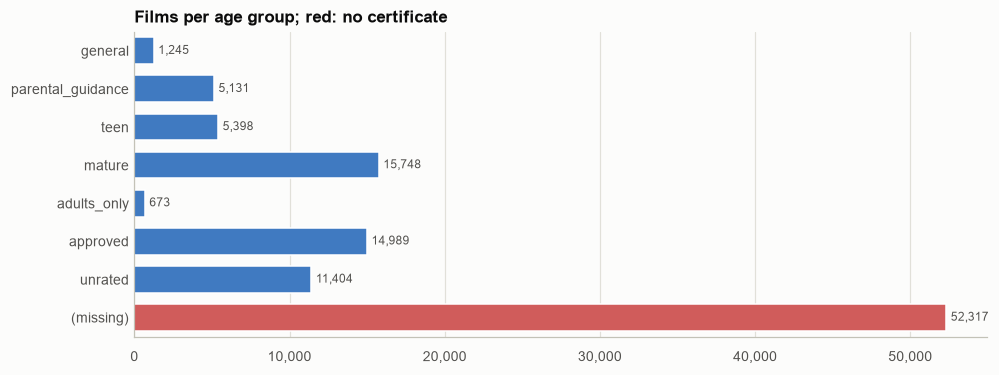

In [29]:
NON_THEATRICAL = re.compile("tv|dvd|video|cable|streaming", re.IGNORECASE)


def us_theatrical(certificates):
    """The first US rating that is not a TV, DVD, video, cable or streaming rating."""
    for entry in certificates:
        if (entry["country"] == "United States" and not entry["rating"].startswith("TV-")
                and not NON_THEATRICAL.search(entry.get("notes") or "")):
            return entry["rating"]
    return None


from_us = clean["certificates_by_country"].map(us_theatrical, na_action="ignore")
to_fill = clean["certificate"].isna() & from_us.notna()
clean.loc[to_fill, "certificate"] = from_us[to_fill]
print(f"Filled {to_fill.sum():,} certificates from US theatrical ratings: {from_us[to_fill].value_counts().to_dict()}")

AGE_GROUPS = {  # group: (minimum age, labels)
    "general": (0, ["G", "TV-G", "TV-Y"]),
    "parental_guidance": (7, ["PG", "GP", "M", "M/PG", "TV-PG", "TV-Y7", "TV-Y7-FV", "E10+"]),
    "teen": (13, ["PG-13", "TV-14", "TV-13", "13+", "T", "12"]),
    "mature": (17, ["R", "TV-MA", "MA-17", "16+"]),
    "adults_only": (18, ["NC-17", "X", "18+"]),
    "approved": (None, ["Approved", "Passed"]),
    "unrated": (None, ["Not Rated", "Unrated", "Open", "(Banned)", "E"]),
}
GROUP_OF = {label: group for group, (_, labels) in AGE_GROUPS.items() for label in labels}
unknown = set(clean["certificate"].dropna()) - set(GROUP_OF)
assert not unknown, f"certificate labels without an age group: {sorted(unknown)}"
clean["age_group"] = clean["certificate"].map(GROUP_OF)
clean["min_age"] = clean["age_group"].map({group: age for group, (age, _) in AGE_GROUPS.items()}).astype("Int64")

films = clean["age_group"].fillna("(missing)").value_counts()
order = [*AGE_GROUPS, "(missing)"]
display(pd.DataFrame({
    "minimum age": [AGE_GROUPS[group][0] if group in AGE_GROUPS else None for group in order],
    "labels": [", ".join(AGE_GROUPS[group][1]) if group in AGE_GROUPS else "" for group in order],
    "films": [int(films.get(group, 0)) for group in order],
}, index=order))

fig, ax = plt.subplots(figsize=(10, 3.6))
sns.barplot(x=[films.get(group, 0) for group in order], y=order, hue=order, legend=False, width=0.7, ax=ax,
            palette=[RED if group == "(missing)" else BLUE for group in order])
for container in ax.containers:
    ax.bar_label(container, fmt="{:,.0f}", padding=3, color=INK_2, fontsize=8)
ax.xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.set(xlabel="", ylabel="")
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", length=0)
ax.set_title("Films per age group; red: no certificate")
plt.show()

## 21. The earliest release date

`release_date` used to hold the release IMDb displays, which is a regional one. It now holds the **earliest** entry of `release_dates`, at its own precision: `1955`, `1955-05` or `1955-05-17`. `release_date_precision` says which, and `release_country` says where.

When a partial date's year or month contains a full date, the full date wins: `1956` and `1956-03-01` give `1956-03-01`. A partial date in an earlier period wins, because that release came first. `first_release_date`, the earliest full date, is now redundant.

In [30]:
PRECISION = {10: "day", 7: "month", 4: "year"}


def period_start(entry):
    return entry["date"] + "-01-01"[: 10 - len(entry["date"])]


def earliest_release(entries):
    """The earliest release; a partial date gives way to a more precise date inside its own year or month."""
    best = min(entries, key=period_start)
    inside = [e for e in entries if len(e["date"]) > len(best["date"]) and e["date"].startswith(best["date"])]
    while inside:
        best = min(inside, key=period_start)
        inside = [e for e in entries if len(e["date"]) > len(best["date"]) and e["date"].startswith(best["date"])]
    return best


earliest = clean["release_dates"].map(earliest_release, na_action="ignore")
has_list = earliest.notna()
clean.loc[has_list, "release_date"] = earliest[has_list].map(lambda entry: entry["date"])
clean.loc[has_list, "release_date_precision"] = earliest[has_list].map(lambda entry: PRECISION[len(entry["date"])])
clean.loc[has_list, "release_date_country"] = earliest[has_list].map(lambda entry: entry["country"])
partial_first = has_list & (clean["release_date_precision"] != "day") & clean["first_release_date"].notna()
clean = clean.rename(columns={"release_date_country": "release_country"}).drop(columns=["first_release_date"])

print(f"Earliest release for {has_list.sum():,} films; without a release list, {(~has_list & clean['release_date'].notna()).sum()} "
      f"film(s) keep the displayed release.")
display(clean["release_date_precision"].value_counts(dropna=False).rename("films").to_frame())
print(f"{partial_first.sum():,} films have a partial date earlier than their earliest full date, for example:")
display(clean.loc[partial_first, ["title", "release_year", "release_date", "release_date_precision", "release_country"]].head(4))

Earliest release for 102,335 films; without a release list, 1 film(s) keep the displayed release.


,films
release_date_precision,
day,92347
month,6179
NaN,4569
year,3810


5,838 films have a partial date earlier than their earliest full date, for example:


,title,release_year,release_date,release_date_precision,release_country
9,From Morning to Midnight,1920,1920,year,Germany
16,The Head of Janus,1920,1920-04,month,Germany
33,Terror Island,1920,1920-04,month,United States
46,A Double-Dyed Deceiver,1920,1920-06,month,United States


## 22. Money, awards and missing values

- **Invalid amounts.** A budget or gross of exactly 0 is never real, in any currency, and a budget under 1,000 USD is a data-entry error. These amounts become missing, with their currency. Small budgets in other currencies stay: judging them would need currency conversion.
- **Opening weekend.** Its currency was always USD, and the column dropped in section 15 held only that. The amount is renamed `opening_weekend_us_canada_usd` so the unit stays visible.
- **Prestigious awards.** When IMDb names no prestigious award, its wins and nominations become 0, like the other award counts.
- **No imputation.** Ratings, money, runtimes, severities and plots stay missing where IMDb has nothing. Inventing them would be wrong.

In [31]:
invalid = {
    "budget_amount": clean["budget_amount"].eq(0) | (clean["budget_currency"].eq("USD") & clean["budget_amount"].lt(1_000)),
    "gross_us_canada_amount": clean["gross_us_canada_amount"].eq(0),
    "gross_worldwide_amount": clean["gross_worldwide_amount"].eq(0),
    "opening_weekend_us_canada_amount": clean["opening_weekend_us_canada_amount"].eq(0),
}
invalid = {amount: flags.fillna(False).to_numpy(dtype=bool) for amount, flags in invalid.items()}
display(clean.loc[invalid["budget_amount"], ["title", "release_year", "budget_amount", "budget_currency"]].head(5))
for amount, flags in invalid.items():
    currency = amount.replace("_amount", "_currency")
    clean.loc[flags, [amount, currency] if currency in clean.columns else [amount]] = None
display(pd.Series({amount: int(flags.sum()) for amount, flags in invalid.items()}, name="invalid amounts removed").to_frame())

clean = clean.rename(columns={"opening_weekend_us_canada_amount": "opening_weekend_us_canada_usd"})

no_award = clean["prestigious_award_name"].isna()
assert clean.loc[no_award, ["prestigious_award_wins", "prestigious_award_nominations"]].isna().all().all()
clean.loc[no_award, ["prestigious_award_wins", "prestigious_award_nominations"]] = 0
print(f"Prestigious-award counts set to 0 for {no_award.sum():,} films without such an award.")

,title,release_year,budget_amount,budget_currency
2032,"Dr. Mabuse, der spieler: Teil II: Inferno",1922,0,DEM
2489,A Pirate for a Day,1922,500,USD
7012,Chang: A Drama of the Wilderness,1927,60,USD
8101,The Old Oregon Trail,1928,800,USD
20817,The Green Hand,1940,0,USD


,invalid amounts removed
budget_amount,73
gross_us_canada_amount,0
gross_worldwide_amount,1
opening_weekend_us_canada_amount,1


Prestigious-award counts set to 0 for 102,045 films without such an award.


## 23. The plot: language, truncation, length and lemmas

- **Language.** A plot made up of at least 20% English stop words is English. Only the others go to langid, which is faster and avoids langid's mistakes on short English sentences.
- **Truncation.** `plot_truncated` marks plots that IMDb cut off with `...`.
- **Length.** `plot_words` counts the words.
- **Lemmas.** For English plots, `plot_lemmas` holds the lowercase lemmas of the words, without stop words and punctuation (spaCy `en_core_web_sm`). It is ready for topic models, search and similarity. This step takes most of the notebook's run time.

In [32]:
plots = clean["plot"].dropna()
tokens = plots.str.lower().str.findall(r"[a-z']+")
stop_share = tokens.map(lambda words: sum(word in STOP_WORDS for word in words) / max(len(words), 1))
language = pd.Series("en", index=plots.index)
uncertain = stop_share < 0.2
language[uncertain] = plots[uncertain].map(lambda text: langid.classify(text)[0])
clean["plot_language"] = language
clean["plot_truncated"] = plots.str.endswith(("...", "…"))
clean["plot_words"] = plots.str.split().str.len()
print(f"{uncertain.sum():,} plots checked with langid; languages: {language.value_counts().head(8).to_dict()}")
print(f"{clean['plot_truncated'].sum():,} plots end with '...'.")

nlp = spacy.load("en_core_web_sm", disable=["parser", "ner"])
english = clean.loc[clean["plot_language"] == "en", "plot"]
lemmas = [" ".join(token.lemma_.lower() for token in doc if token.is_alpha and not token.is_stop) or None
          for doc in nlp.pipe(english.tolist(), batch_size=1_000)]
clean["plot_lemmas"] = pd.Series(lemmas, index=english.index)
display(clean.loc[[example], ["title", "plot", "plot_lemmas"]])

615 plots checked with langid; languages: {'en': 95750, 'es': 121, 'fr': 26, 'de': 23, 'fi': 7, 'no': 5, 'pt': 4, 'nl': 4}
786 plots end with '...'.


,title,plot,plot_lemmas
74048,The Shawshank Redemption,"After a banker is sentenced to life in Shawshank Prison,...",banker sentence life shawshank prison form unlikely frie...


## 24. A search key for titles

`title_key` makes titles easy to match and search:

1. NFKC folds compatibility characters (`８` becomes `8`, `ﬁ` becomes `fi`).
2. unidecode transliterates to ASCII (`é` becomes `e`, `Москва` becomes `Moskva`).
3. Case folding lowercases.
4. Punctuation becomes spaces.

The title itself keeps its original spelling.

In [33]:
def search_key(text):
    """NFKC, ASCII transliteration, case folding and punctuation removed: a key for matching titles."""
    text = unidecode(unicodedata.normalize("NFKC", text)).casefold()
    return " ".join(re.sub(r"[^0-9a-z]+", " ", text).split()) or None


clean["title_key"] = clean["title"].map(search_key, na_action="ignore")
examples = clean["title"].str.contains(r"[^\x00-\x7f]") & clean["title"].str.len().lt(30)
display(clean.loc[examples, ["title", "title_key"]].drop_duplicates("title").sample(6, random_state=1))
print(f"{clean['title_key'].duplicated(keep=False).sum():,} films share their key with another film (same title, different film).")

,title,title_key
102380,¡Viva Maestro!,viva maestro
40653,Das Rätsel der grünen Spinne,das ratsel der grunen spinne
3883,Tsumi ni sâsu kage,tsumi ni sasu kage
76546,Pédale douce,pedale douce
132,Die Tänzerin Barberina,die tanzerin barberina
37788,En drömmares vandring,en drommares vandring


17,492 films share their key with another film (same title, different film).


## 25. Optimize the types

This is the last step before the export, so that no earlier step has to work around a narrow type:

- **Integers:** the smallest nullable type that holds them (`Int8`, `Int16`, `Int32` or `Int64`).
- **The rating:** `Float32`.
- **Fixed sets of values:** `category`. The severities become an ordered category (none < mild < moderate < severe).
- **`plot_truncated`:** `boolean`.
- **Free text:** `string`.

The list and record columns stay Python objects in memory: JSON text in the CSV, nested columns in the Parquet file.

In [34]:
COLUMNS = [
    "imdb_id", "title", "original_title", "title_key",
    "release_year", "release_date", "release_date_precision", "release_country", "runtime_minutes",
    "plot", "plot_language", "plot_truncated", "plot_words", "plot_lemmas", "poster_url",
    "genres", "interests", "keywords", "keywords_total", "countries_of_origin", "languages",
    "production_companies", "filming_location", "filming_locations_total",
    "imdb_rating", "imdb_votes", "rating_histogram", "metascore", "top_rated_rank",
    "user_reviews_count", "critic_reviews_count",
    "certificate", "age_group", "min_age", *SEVERITY_COLUMNS, "certificates_by_country", "certificates_total",
    "budget_amount", "budget_currency", "gross_us_canada_amount", "gross_us_canada_currency",
    "gross_worldwide_amount", "gross_worldwide_currency", "opening_weekend_us_canada_usd", "opening_weekend_end_date",
    "award_wins", "award_nominations", "prestigious_award_name", "prestigious_award_wins", "prestigious_award_nominations",
    *CREDIT_GROUPS, "similar_movies", "release_dates", "akas",
]
NESTED = ["genres", "interests", "keywords", "countries_of_origin", "languages", "production_companies",
          "rating_histogram", "certificates_by_country", *CREDIT_GROUPS, "similar_movies", "release_dates", "akas"]
assert set(COLUMNS) == set(clean.columns), set(COLUMNS) ^ set(clean.columns)
clean = clean[COLUMNS].reset_index(drop=True)
scalar_columns = [column for column in COLUMNS if column not in NESTED]
memory_before = clean[scalar_columns].memory_usage(deep=True).sum() / 1e6
types_before = clean.dtypes.astype(str)

INTEGER = ["release_year", "runtime_minutes", "plot_words", "keywords_total", "filming_locations_total", "imdb_votes",
           "metascore", "top_rated_rank", "user_reviews_count", "critic_reviews_count", "min_age", "certificates_total",
           "budget_amount", "gross_us_canada_amount", "gross_worldwide_amount", "opening_weekend_us_canada_usd",
           "award_wins", "award_nominations", "prestigious_award_wins", "prestigious_award_nominations"]
CATEGORY = ["release_date_precision", "release_country", "plot_language", "certificate", "age_group",
            "budget_currency", "gross_us_canada_currency", "gross_worldwide_currency", "prestigious_award_name"]
TEXT = ["imdb_id", "title", "original_title", "title_key", "release_date", "plot", "plot_lemmas", "poster_url",
        "filming_location"]
SEVERITY = pd.CategoricalDtype(["none", "mild", "moderate", "severe"], ordered=True)

for column in INTEGER:
    values = pd.to_numeric(clean[column]).astype("Int64")
    clean[column] = values.astype(smallest_int(values))
clean["imdb_rating"] = clean["imdb_rating"].astype("Float32")
for column in CATEGORY:
    clean[column] = clean[column].astype("category")
for column in SEVERITY_COLUMNS:
    clean[column] = clean[column].astype(SEVERITY)
clean["plot_truncated"] = clean["plot_truncated"].astype("boolean")
for column in TEXT:
    clean[column] = clean[column].astype("string")

memory_after = clean[scalar_columns].memory_usage(deep=True).sum() / 1e6
print(f"{len(clean):,} films x {clean.shape[1]} columns. The {len(scalar_columns)} columns that are not lists or records "
      f"take {memory_before:,.0f} MB before and {memory_after:,.0f} MB after.")
changed_types = pd.DataFrame({"before": types_before, "after": clean.dtypes.astype(str)})
display(changed_types[changed_types["before"] != changed_types["after"]].T)

106,905 films x 67 columns. The 46 columns that are not lists or records take 110 MB before and 77 MB after.


,imdb_id,title,original_title,title_key,release_year,release_date,release_date_precision,release_country,runtime_minutes,plot,...,budget_currency,gross_us_canada_amount,gross_us_canada_currency,gross_worldwide_currency,opening_weekend_us_canada_usd,award_wins,award_nominations,prestigious_award_name,prestigious_award_wins,prestigious_award_nominations
before,str,str,str,str,Int64,str,str,str,Float64,str,...,str,Int64,str,str,Int64,Int64,Int64,str,Int64,Int64
after,string,string,string,string,Int16,string,category,category,Int32,string,...,category,Int32,category,category,Int32,Int16,Int16,category,Int8,Int8


## 26. Quality checks on the clean table

The cleaned table is checked one last time, after every step and the type changes, against two kinds of checks:

- **Rules** must hold for every film; a rule with failures is a problem.
- **Notices** are not errors: they count films worth knowing about, for example an opening weekend larger than the total gross.

The checks count failures instead of stopping the notebook, so that every problem shows up at once.

In [35]:
TT, NM = re.compile(r"tt\d{7,}"), re.compile(r"nm\d{7,}")
LABEL_COLUMNS = ["genres", "interests", "keywords", "countries_of_origin", "languages", "production_companies"]
AMOUNT_PAIRS = {"budget_amount": "budget_currency", "gross_us_canada_amount": "gross_us_canada_currency",
                "gross_worldwide_amount": "gross_worldwide_currency"}


def flags(values):
    """Any boolean-like sequence as a plain boolean Series on the clean index; missing counts as False."""
    return pd.Series(values, index=clean.index).astype("boolean").fillna(False).astype(bool)


def release_date_problem(date, precision):
    if pd.isna(date):
        return False
    if PRECISION.get(len(date)) != precision:
        return True
    try:
        pd.Timestamp(date + "-01-01"[: 10 - len(date)])
        return False
    except ValueError:
        return True


def min_age_problem(group, age):
    expected = None if pd.isna(group) else AGE_GROUPS[group][0]
    actual = None if pd.isna(age) else int(age)
    return expected != actual


def bad_people(records):
    return any(not NM.fullmatch(record["id"] or "") or not record["name"] for record in records)


def bad_labels(values):
    return any(not value or value != value.strip() for value in values) or len(set(values)) != len(values)


votes, rating = clean["imdb_votes"], clean["imdb_rating"]
histogram = clean["rating_histogram"]
release_year_gap = (pd.to_numeric(clean["release_date"].str[:4]) - clean["release_year"]).abs()
RULES = {
    "imdb_id unique and well formed": clean["imdb_id"].duplicated(keep=False) | ~clean["imdb_id"].str.fullmatch(TT.pattern),
    "title present": clean["title"].isna(),
    "rating between 1 and 10": ~rating.between(1, 10) & rating.notna(),
    "rating present exactly when there are votes": (votes.gt(0) & rating.isna()) | (votes.eq(0) & rating.notna()),
    "Metascore between 0 and 100": ~clean["metascore"].between(0, 100) & clean["metascore"].notna(),
    "runtime of at least 40 minutes": clean["runtime_minutes"].lt(40),
    "release date matches its precision and exists": [release_date_problem(d, p) for d, p in
                                                      zip(clean["release_date"], clean["release_date_precision"])],
    "certificate has an age group": clean["certificate"].notna() & clean["age_group"].isna(),
    "min_age matches the age group": [min_age_problem(g, a) for g, a in zip(clean["age_group"], clean["min_age"])],
    "amounts positive, each with its currency": pd.concat(
        [clean[amount].le(0) | (clean[amount].isna() != clean[currency].isna()) for amount, currency in AMOUNT_PAIRS.items()]
        + [clean["opening_weekend_us_canada_usd"].le(0)], axis=1).fillna(False).any(axis=1),
    "counts not negative": clean[["imdb_votes", "user_reviews_count", "critic_reviews_count", "award_wins",
                                  "award_nominations", "prestigious_award_wins", "prestigious_award_nominations"]]
                           .lt(0).fillna(False).any(axis=1),
    "rating histogram: 10 values summing to the votes (within 2% + 5)": [
        isinstance(h, list) and (len(h) != 10 or abs(sum(h) - v) > 0.02 * v + 5) for h, v in zip(histogram, votes)],
    "people have an nm... ID and a name": pd.concat([clean[group].map(bad_people, na_action="ignore") for group in CREDIT_GROUPS],
                                                    axis=1).fillna(False).astype(bool).any(axis=1),
    "similar movies have a tt... ID and are not the film itself": [
        isinstance(movies_list, list) and any(not TT.fullmatch(m["id"]) or m["id"] == film for m in movies_list)
        for film, movies_list in zip(clean["imdb_id"], clean["similar_movies"])],
    "label lists without empty, untrimmed or repeated entries": pd.concat(
        [clean[column].map(bad_labels, na_action="ignore") for column in LABEL_COLUMNS], axis=1).fillna(False).astype(bool).any(axis=1),
    "title key present": clean["title_key"].isna(),
}
NOTICES = {
    "no certificate": clean["certificate"].isna(),
    "plot not in English": clean["plot_language"].notna() & clean["plot_language"].ne("en"),
    "English plot without lemmas (only stop words)": clean["plot_language"].eq("en") & clean["plot_lemmas"].isna(),
    "release date known only to the month or year": clean["release_date_precision"].isin(["month", "year"]),
    "earliest release more than a year away from release_year": release_year_gap.gt(1),
    "runtime over 400 minutes": clean["runtime_minutes"].gt(400),
    "opening weekend above the total US gross (both in USD)": clean["opening_weekend_us_canada_usd"].gt(clean["gross_us_canada_amount"])
                                                            & clean["gross_us_canada_currency"].eq("USD"),
    "budget under 1,000 in another currency": clean["budget_amount"].lt(1_000) & clean["budget_currency"].ne("USD"),
    "gross in another currency than USD": clean["gross_us_canada_currency"].ne("USD") & clean["gross_us_canada_currency"].notna()
                                         | clean["gross_worldwide_currency"].ne("USD") & clean["gross_worldwide_currency"].notna(),
}


def examples(failing):
    rows = clean.loc[failing, ["title", "imdb_id"]].head(3)
    return [f"{title} ({imdb_id})" for title, imdb_id in rows.itertuples(index=False)]


checks = pd.DataFrame(
    [{"check": name, "kind": kind, "films": int(flags(values).sum()), "examples": examples(flags(values))}
     for kind, table in (("rule", RULES), ("notice", NOTICES)) for name, values in table.items()]
)

# The text rules apply to every string left in the table, including inside the lists and records
final_texts = strings(clean, clean, ["title", "original_title", "plot", "filming_location", "certificate",
                                     "prestigious_award_name", "release_country"],
                      [*LABEL_COLUMNS, *CREDIT_GROUPS, "similar_movies", "akas", "release_dates", "certificates_by_country"])
characters = clean["cast"].explode().dropna().map(lambda person: person["characters"]).explode().dropna()
final_texts = pd.concat([final_texts, characters.rename("text").to_frame().assign(column="cast.characters")], ignore_index=True)
final_suspect = final_texts[final_texts["text"].str.contains(SUSPECT_PATTERN, regex=True)]
text_problems = text_issues(final_suspect).drop(columns=["zero-width joiners", "changes under NFKC"]).rename(columns={"not NFC": "non-NFC text"})
text_problems["stray zero-width joiners"] = final_suspect["text"].str.contains(STRAY_JOINER.pattern)
string_rules = pd.DataFrame([
    {"check": f"strings without {issue}", "kind": "rule", "films": int(hits.sum()),
     "examples": final_suspect.loc[hits, "text"].str[:40].head(3).tolist()}
    for issue, hits in text_problems.items()
] + [{"check": "no empty strings", "kind": "rule", "films": int(final_texts["text"].eq("").sum()), "examples": []}])
checks = pd.concat([checks, string_rules], ignore_index=True).rename(columns={"films": "failing"})
print(f"{len(final_texts):,} strings checked. Rules with failures: {int((checks['kind'].eq('rule') & checks['failing'].gt(0)).sum())}.")
with pd.option_context("display.max_rows", 60, "display.max_colwidth", 80):
    display(checks)
del final_texts, final_suspect, characters

23,665,402 strings checked. Rules with failures: 1.


,check,kind,failing,examples
0,imdb_id unique and well formed,rule,0,[]
1,title present,rule,0,[]
2,rating between 1 and 10,rule,0,[]
3,rating present exactly when there are votes,rule,0,[]
4,Metascore between 0 and 100,rule,0,[]
5,runtime of at least 40 minutes,rule,0,[]
6,release date matches its precision and exists,rule,0,[]
7,certificate has an age group,rule,0,[]
8,min_age matches the age group,rule,0,[]
9,"amounts positive, each with its currency",rule,0,[]


## 27. Export

The CSV stores the list and record columns as JSON text, like the original dataset. The Parquet file keeps every type, including the nested lists and records. The data dictionary describes every column.

In [36]:
DESCRIPTIONS = {
    "imdb_id": "IMDb title ID (tt followed by digits); one row per film.",
    "title": "Title shown on IMDb.",
    "original_title": "Title in its original language.",
    "title_key": "Search key for matching titles: NFKC, transliterated to ASCII, lowercase, punctuation replaced by spaces.",
    "release_year": "Release year according to IMDb's title page.",
    "release_date": "Earliest known release date, ISO text at its own precision: YYYY, YYYY-MM or YYYY-MM-DD.",
    "release_date_precision": "Precision of release_date: year, month or day.",
    "release_country": "Country of the earliest known release.",
    "runtime_minutes": "Runtime in minutes.",
    "plot": "Plot outline.",
    "plot_language": "Language of the plot as an ISO 639-1 code (en, es, ...), from an English stop-word check and langid.",
    "plot_truncated": "True when IMDb cut the plot off with '...'.",
    "plot_words": "Number of words in the plot.",
    "plot_lemmas": "Lowercase lemmas of the plot without stop words and punctuation (spaCy en_core_web_sm); English plots only.",
    "poster_url": "URL of the film's main image on IMDb.",
    "genres": "IMDb genres.",
    "interests": "IMDb interests (themes, sub-genres and franchises), without the genre names already in genres.",
    "keywords": "The first plot keywords IMDb shows (see keywords_total).",
    "keywords_total": "Number of plot keywords IMDb holds for the film.",
    "countries_of_origin": "Countries of origin, with historical names as IMDb gives them (for example West Germany).",
    "languages": "Spoken languages; silent_movie for films without spoken language.",
    "production_companies": "Production companies.",
    "filming_location": "First filming location IMDb lists (see filming_locations_total).",
    "filming_locations_total": "Number of filming locations IMDb holds for the film.",
    "imdb_rating": "IMDb weighted user rating, 1 to 10; missing when the film has no votes.",
    "imdb_votes": "Number of user ratings; 0 when the film has none.",
    "rating_histogram": "Votes for each rating from 1 to 10.",
    "metascore": "Metacritic Metascore, 0 to 100.",
    "top_rated_rank": "Position in IMDb's Top Rated list.",
    "user_reviews_count": "Number of user reviews.",
    "critic_reviews_count": "Number of critic reviews.",
    "certificate": "US certificate as IMDb labels it (PG-13, Approved, TV-MA, ...), filled from US theatrical ratings when the title page had none.",
    "age_group": "Audience group of the certificate: general, parental_guidance, teen, mature, adults_only, approved (Production Code clearance, no age) or unrated.",
    "min_age": "Minimum age of the age group (0, 7, 13, 17 or 18); missing for approved and unrated.",
    "sex_nudity_severity": "Severity of sex and nudity in IMDb's parental guide: none < mild < moderate < severe.",
    "violence_gore_severity": "Severity of violence and gore in IMDb's parental guide: none < mild < moderate < severe.",
    "profanity_severity": "Severity of profanity in IMDb's parental guide: none < mild < moderate < severe.",
    "alcohol_drugs_smoking_severity": "Severity of alcohol, drugs and smoking in IMDb's parental guide: none < mild < moderate < severe.",
    "frightening_intense_scenes_severity": "Severity of frightening and intense scenes in IMDb's parental guide: none < mild < moderate < severe.",
    "certificates_by_country": "Certificates from IMDb's parental guide, one record per country rating (IMDb shows the first 50).",
    "certificates_total": "Number of countries with a certificate according to IMDb.",
    "budget_amount": "Production budget, in budget_currency (not converted).",
    "budget_currency": "ISO 4217 code of the budget's currency.",
    "gross_us_canada_amount": "Lifetime gross in the US and Canada, in gross_us_canada_currency.",
    "gross_us_canada_currency": "ISO 4217 code of the US and Canada gross (almost always USD).",
    "gross_worldwide_amount": "Lifetime worldwide gross, in gross_worldwide_currency.",
    "gross_worldwide_currency": "ISO 4217 code of the worldwide gross (almost always USD).",
    "opening_weekend_us_canada_usd": "Opening-weekend gross in the US and Canada, in USD.",
    "opening_weekend_end_date": "Last day of the opening weekend.",
    "award_wins": "Total award wins; 0 when IMDb lists none.",
    "award_nominations": "Award nominations that did not result in a win; 0 when IMDb lists none.",
    "prestigious_award_name": "The award IMDb singles out for the film (Oscar, BAFTA Film Award, ...).",
    "prestigious_award_wins": "Wins of that award; 0 when IMDb singles out none.",
    "prestigious_award_nominations": "Nominations for that award; 0 when IMDb singles out none.",
    **{group: f"{group.replace('_', ' ').capitalize()}, in the order of IMDb's full credits." for group in CREDIT_GROUPS},
    "cast": "Cast in the order of IMDb's full credits, with the characters each person played.",
    "similar_movies": "IMDb's 'More like this' films, in IMDb's order.",
    "release_dates": "Every release on IMDb: country, ISO date (possibly partial) and note.",
    "akas": "Alternative titles: country, title and note.",
}
NESTED_TYPES = {
    "genres": "list of text", "interests": "list of text", "keywords": "list of text", "countries_of_origin": "list of text",
    "languages": "list of text", "production_companies": "list of text", "rating_histogram": "list of 10 integers",
    "certificates_by_country": "list of {country, rating, notes}", "release_dates": "list of {country, date, note}",
    "akas": "list of {country, title, note}", "similar_movies": "list of {id, title}",
    **{group: "list of {id, name}" for group in CREDIT_GROUPS}, "cast": "list of {id, name, characters}",
}


def type_name(column, dtype):
    if column in NESTED_TYPES:
        return NESTED_TYPES[column]
    if isinstance(dtype, pd.CategoricalDtype) and dtype.ordered:
        return "ordered category: " + " < ".join(dtype.categories)
    return str(dtype)


dictionary = pd.DataFrame({
    "column": clean.columns,
    "type": [type_name(column, dtype) for column, dtype in clean.dtypes.items()],
    "description": [DESCRIPTIONS[column] for column in clean.columns],
})
stem = OUTPUT_DIR / "imdb_movies_1920_2026_clean"
as_text = clean.copy()
for column in NESTED_TYPES:
    as_text[column] = as_text[column].map(lambda value: json.dumps(value, ensure_ascii=False), na_action="ignore")
as_text.to_csv(f"{stem}.csv", index=False, lineterminator="\n")
clean.to_parquet(f"{stem}.parquet", index=False)
dictionary.to_csv(f"{stem}_dictionary.csv", index=False)
del as_text

for suffix in (".csv", ".parquet", "_dictionary.csv"):
    path = Path(f"{stem}{suffix}")
    print(f"{path.name}: {path.stat().st_size / 1e6:,.1f} MB")
with pd.option_context("display.max_rows", 80, "display.max_colwidth", 120):
    display(dictionary)

imdb_movies_1920_2026_clean.csv: 784.6 MB
imdb_movies_1920_2026_clean.parquet: 181.7 MB
imdb_movies_1920_2026_clean_dictionary.csv: 0.0 MB


,column,type,description
0,imdb_id,string,IMDb title ID (tt followed by digits); one row per film.
1,title,string,Title shown on IMDb.
2,original_title,string,Title in its original language.
3,title_key,string,"Search key for matching titles: NFKC, transliterated to ASCII, lowercase, punctuation replaced by spaces."
4,release_year,Int16,Release year according to IMDb's title page.
5,release_date,string,"Earliest known release date, ISO text at its own precision: YYYY, YYYY-MM or YYYY-MM-DD."
6,release_date_precision,category,"Precision of release_date: year, month or day."
7,release_country,category,Country of the earliest known release.
8,runtime_minutes,Int32,Runtime in minutes.
9,plot,string,Plot outline.


A last check: both files read back with every film and column. The Parquet file keeps the types, and the CSV's JSON columns parse back into the same lists and records.

In [37]:
from_parquet = pd.read_parquet(f"{stem}.parquet")
from_csv = pd.read_csv(f"{stem}.csv", dtype=str, keep_default_na=False, na_values=[""])
assert from_parquet.shape == from_csv.shape == clean.shape
pd.testing.assert_frame_equal(from_parquet[scalar_columns], clean[scalar_columns], check_dtype=False)
assert all(from_parquet[column].notna().sum() == clean[column].notna().sum() for column in NESTED_TYPES)
assert all(from_csv[column].map(json.loads, na_action="ignore").equals(clean[column]) for column in NESTED_TYPES)
print(f"Both files hold {len(clean):,} films x {clean.shape[1]} columns; the Parquet types are "
      f"{'kept' if (from_parquet[scalar_columns].dtypes.astype(str) == clean[scalar_columns].dtypes.astype(str)).all() else 'partly changed'}.")

Both files hold 106,905 films x 67 columns; the Parquet types are kept.


## 28. Before and after

The whole cleanup at a glance: the totals, what each step changed, and the missing share of every column before (in the combined file) and after.

In [38]:
input_size = INPUT_FILE.stat().st_size / 1e6
output_sizes = {suffix: Path(f"{stem}{suffix}").stat().st_size / 1e6 for suffix in (".csv", ".parquet")}
display(pd.DataFrame({
    "before": [f"{n_films:,}", "98", f"{input_size:,.0f} MB (CSV)"],
    "after": [f"{len(clean):,}", f"{clean.shape[1]}",
              f"{output_sizes['.csv']:,.0f} MB (CSV), {output_sizes['.parquet']:,.0f} MB (Parquet)"],
}, index=["films", "columns", "file size"]))

display(pd.DataFrame([
    ("14", "films removed (never released or under 40 minutes)", int(removed.sum())),
    ("15", "columns removed", sum(len(columns) for columns in DROPPED.values())),
    ("17", "strings repaired or normalized", sum(CHANGES.values())),
    ("18", "spellings unified", sum(len(mapping) for _, mapping in unified)),
    ("19", "'original title' rows removed from akas", int(has_row.sum())),
    ("19", "genre names removed from interests", interests_before - int(clean["interests"].explode().notna().sum())),
    ("19", "films with silent_movie", int(clean["languages"].map(lambda values: "silent_movie" in values, na_action="ignore").sum())),
    ("20", "certificates filled from US theatrical ratings", int(to_fill.sum())),
    ("21", "release dates set to the earliest release", int(has_list.sum())),
    ("22", "invalid amounts removed", sum(int(found.sum()) for found in invalid.values())),
    ("22", "prestigious-award counts set to 0", int(no_award.sum())),
    ("23", "plots checked with langid", int(uncertain.sum())),
    ("23", "plots lemmatized", int(clean["plot_lemmas"].notna().sum())),
], columns=["section", "change", "count"]))

RENAMED = {"opening_weekend_us_canada_usd": "opening_weekend_us_canada_amount", "release_country": "release_date_country",
           "filming_location": "filming_locations", "similar_movies": "similar_movie_ids"}
missing_change = pd.DataFrame({
    "missing % before": [inventory["missing %"].get(RENAMED.get(column, column)) for column in clean.columns],
    "missing % after": clean.isna().mean().mul(100).round(1).to_numpy(),
}, index=clean.columns)
missing_change["change"] = (missing_change["missing % after"] - missing_change["missing % before"]).round(1)
with pd.option_context("display.max_rows", 80):
    display(missing_change)

,before,after
films,"106,999","106,905"
columns,98,67
file size,642 MB (CSV),"785 MB (CSV), 182 MB (Parquet)"


,section,change,count
0,14,films removed (never released or under 40 minutes),94
1,15,columns removed,25
2,17,strings repaired or normalized,2065
3,18,spellings unified,15889
4,19,'original title' rows removed from akas,106904
5,19,genre names removed from interests,226284
6,19,films with silent_movie,8907
7,20,certificates filled from US theatrical ratings,85
8,21,release dates set to the earliest release,102335
9,22,invalid amounts removed,75


,missing % before,missing % after,change
imdb_id,0.0,0.0,0.0
title,0.0,0.0,0.0
original_title,0.0,0.0,0.0
title_key,NaN,0.0,NaN
release_year,0.0,0.0,0.0
release_date,4.3,4.3,0.0
release_date_precision,4.3,4.3,0.0
release_country,4.3,4.3,0.0
runtime_minutes,7.0,7.0,0.0
plot,10.2,10.2,0.0


## Using the clean data

```python
import json
import pandas as pd

movies = pd.read_parquet("imdb_movies_1920_2026_clean.parquet")   # types kept; lists and records are nested

# Or the CSV: read as text, then parse the JSON columns you need
movies = pd.read_csv("imdb_movies_1920_2026_clean.csv", keep_default_na=False, na_values=[""], low_memory=False)
movies["cast"] = movies["cast"].map(json.loads, na_action="ignore")
```

The data dictionary, `imdb_movies_1920_2026_clean_dictionary.csv`, gives every column's type and meaning.